# Dispensação de medicamentos na rede municipal — o que os dados mostram

**Pergunta que guia esta análise:** como o volume de medicamentos dispensados varia
ao longo do tempo, quais padrões se repetem, quais mudanças fogem do esperado, e o
que isso pode significar para quem depende desse serviço?

**Como este notebook está organizado:**
1. Preparação dos dados e checagem de completude (quais meses estão fechados e
   qual está parcial).
2. Funções de apoio reutilizadas em todos os gráficos (evita números diferentes
   para a mesma conta em lugares diferentes do notebook).
3. Tendência e anomalias no volume total da rede, e por recorte (bairro, tipo de
   material, centro de custo, classe terapêutica).
4. Relatório final, com os números **gerados diretamente pelo código acima**
   (não digitados à mão), separando o que os dados comprovam do que é hipótese
   e ainda precisa de outra fonte para ser confirmado.

**Nota metodológica importante — mês parcial:** se o arquivo for extraído no meio
de um mês, esse mês aparece na base com menos dias que os demais. Comparar um mês
parcial com meses completos (ex.: 15 dias de agosto contra 31 dias completos de
julho) faria parecer que houve uma "queda", quando na verdade é só o mês ainda não
ter terminado. Por isso, o mês em andamento é **identificado explicitamente** nos
gráficos (área sombreada / marcador vazado) e **excluído dos cálculos de média,
variação percentual e detecção de anomalias**, entrando de volta assim que a base
for atualizada com o mês completo.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from collections import defaultdict
from IPython.display import Markdown, display

# ============================================================
# ESTILO GLOBAL: aplica a TODOS os gráficos do notebook
# ============================================================
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': '#fbfbfc',
    'axes.edgecolor': '#444444',
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.linestyle': '--',
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'font.size': 11,
    'legend.frameon': True,
    'legend.framealpha': 0.92,
    'legend.edgecolor': '#cccccc',
    'xtick.color': '#333333',
    'ytick.color': '#333333',
})

# Paleta com cores bem distinguíveis entre si (até 18 séries diferentes)
PALETA = list(plt.get_cmap('tab10').colors) + list(plt.get_cmap('Dark2').colors)

## 1. Carregar os dados e checar completude

In [2]:
def identificar_mes_parcial(df, coluna_data='data'):
    '''
    Identifica se o ÚLTIMO mês presente na base está incompleto (arquivo
    extraído no meio do mês). Retorna o Period do mês parcial, ou None se o
    último mês já fechou.
    '''
    ultima_data = df[coluna_data].max()
    ultimo_dia_do_mes = ultima_data.to_period('M').end_time.normalize()
    if ultima_data.normalize() < ultimo_dia_do_mes:
        mes = ultima_data.to_period('M')
        dias_disponiveis = df.loc[df[coluna_data].dt.to_period('M') == mes, coluna_data].dt.normalize().nunique()
        print(f"[aviso] {mes} está PARCIAL na base: {dias_disponiveis} dia(s) com "
              f"registro, de um total de {ultimo_dia_do_mes.day} dias no mês "
              f"(dados até {ultima_data.strftime('%d/%m/%Y')}).")
        print(f"        Esse mês será destacado nos gráficos e EXCLUÍDO das médias, "
              f"variações percentuais e da detecção de anomalias, para não distorcer "
              f"as comparações.")
        return mes
    return None


# 1. Carregar os dados já preparados
df = pd.read_csv('../../data/processed/dispensacao_analitico.csv', parse_dates=['data'])

MES_PARCIAL = identificar_mes_parcial(df)

df.info()

# 2. Checagem de completude por mês -- confere quantos dias de dado existem em
#    cada mês da base (serve para auditar visualmente a marcação acima)
checagem = (df.groupby(df['data'].dt.to_period('M'))['data']
              .nunique().rename('dias_com_registro').to_frame())
checagem['dias_no_mes'] = checagem.index.map(lambda p: p.days_in_month)
checagem['status'] = np.where(checagem.index == MES_PARCIAL, 'PARCIAL (mês em andamento)',
                        np.where(checagem['dias_com_registro'] >= checagem['dias_no_mes'] - 2,
                                 'completo', 'completo, com feriados/fechamentos'))
checagem

[aviso] 2026-08 está PARCIAL na base: 2 dia(s) com registro, de um total de 31 dias no mês (dados até 04/08/2026).
        Esse mês será destacado nos gráficos e EXCLUÍDO das médias, variações percentuais e da detecção de anomalias, para não distorcer as comparações.
<class 'pandas.DataFrame'>
RangeIndex: 220815 entries, 0 to 220814
Data columns (total 25 columns):
 #   Column                           Non-Null Count   Dtype         
---  ------                           --------------   -----         
 0   competencia_inicial              220815 non-null  int64         
 1   competencia_final                219080 non-null  float64       
 2   ups_nome                         220815 non-null  str           
 3   ups_codigo                       220815 non-null  int64         
 4   bairro_nome                      220815 non-null  str           
 5   bairro_codigo                    220792 non-null  float64       
 6   centro_custo_nome                220815 non-null  str           
 7

,dias_com_registro,dias_no_mes,status
data,,,
2025-08,21,31,"completo, com feriados/fechamentos"
2025-09,22,30,"completo, com feriados/fechamentos"
2025-10,22,31,"completo, com feriados/fechamentos"
2025-11,19,30,"completo, com feriados/fechamentos"
2025-12,20,31,"completo, com feriados/fechamentos"
2026-01,20,31,"completo, com feriados/fechamentos"
2026-02,18,28,"completo, com feriados/fechamentos"
2026-03,22,31,"completo, com feriados/fechamentos"
2026-04,20,30,"completo, com feriados/fechamentos"


### Auditoria de ordenação: confirmando que o critério é "por quantidade", não alfabético

A tabela abaixo existe só para conferência: mostra, para cada recorte usado nos
gráficos (bairro, tipo de material, centro de custo, classe terapêutica), a
ordem exata em que os grupos entram nos gráficos de "top N". Se algum gráfico
parecer estar mostrando os grupos errados, comparar com esta tabela ajuda a
apontar exatamente onde a ordenação diverge do volume total.

In [3]:
def auditar_ordenacao(df, coluna, top=8):
    ranking = (df.groupby(coluna)['quantidade'].sum()
                 .sort_values(ascending=False)
                 .rename('quantidade_total').reset_index())
    ranking.insert(0, 'posicao_no_grafico', range(1, len(ranking) + 1))
    return ranking.head(top)

for coluna_auditada in ['bairro_nome', 'material_tipo', 'centro_custo_nome', 'classe_terapeutica']:
    print(f"--- Ordem usada nos gráficos de '{coluna_auditada}' (por quantidade total, maior -> menor) ---")
    display(auditar_ordenacao(df, coluna_auditada))

--- Ordem usada nos gráficos de 'bairro_nome' (por quantidade total, maior -> menor) ---


,posicao_no_grafico,bairro_nome,quantidade_total
0,1,COLONINHA,1412274
1,2,URUSSANGUINHA,756046
2,3,MATO ALTO LAGOÃO,686288
3,4,POLICIA RODOVIARIA,629098
4,5,JARDIM DAS AVENIDAS,608386
5,6,VILA SAO JOSE,486172
6,7,LAGOAO,467796
7,8,CIDADE ALTA,466004


--- Ordem usada nos gráficos de 'material_tipo' (por quantidade total, maior -> menor) ---


,posicao_no_grafico,material_tipo,quantidade_total
0,1,COMPRIMIDO,9171137
1,2,CAPSULA,727995
2,3,UNIDADE,228965
3,4,FRASCO,38928
4,5,AMPOLA,4411
5,6,SACHE,2750
6,7,BISNAGA,1475
7,8,TUBO,474


--- Ordem usada nos gráficos de 'centro_custo_nome' (por quantidade total, maior -> menor) ---


,posicao_no_grafico,centro_custo_nome,quantidade_total
0,1,Sem Centro de Custo,8347906
1,2,CAPS,1123768
2,3,AMB. ALCOOL E DROGAS,299867
3,4,PRESIDIO,194063
4,5,FAZENDA SÃO JORGE,137573
5,6,APAE,70623
6,7,saude mental,772
7,8,ASILO,525


--- Ordem usada nos gráficos de 'classe_terapeutica' (por quantidade total, maior -> menor) ---


,posicao_no_grafico,classe_terapeutica,quantidade_total
0,1,ANTIDEPRESSIVOS,1971551
1,2,ANTICONVULSIVANTES,901745
2,3,ANALGESICOS NAO NARCOTICOS,778548
3,4,HORMONIOS TIREOIDEANOS SIMPLES OU ASSOCIADOS E...,582964
4,5,ANTI-HIPERTENSIVOS,492084
5,6,ANTIULCEROSOS,488984
6,7,ANTILIPEMICOS,456377
7,8,NEUROLEPTICOS,398635


## 2. Funções de apoio

Essas funções são usadas em **todos** os gráficos do notebook — assim, a mesma
conta (variação %, índice, z-score, detecção de mês parcial) é feita uma única
vez e reaproveitada, evitando que o mesmo número apareça diferente em lugares
diferentes.

In [4]:
def calcular_serie_mensal(df, metodo='indice', populacao=None, nome_serie=None, mes_parcial=None):
    '''
    Agrega a quantidade por mês e aplica normalização.

    metodo:
      'bruto'      -> quantidade total mensal, sem normalizar (valor absoluto).
      'indice'     -> índice-base 100: quantidade / média histórica da PRÓPRIA série * 100.
                      Não depende de dado externo e permite comparar a TENDÊNCIA de bairros
                      com volumes muito diferentes na mesma escala.
      'per_capita' -> quantidade / população * 10.000 (dispensações a cada 10 mil habitantes).
                      Requer um dicionário `populacao` = {nome_da_serie: nº de habitantes}.
                      Se a população não estiver cadastrada, cai automaticamente para 'indice'.

    mes_parcial: Period do mês em andamento (ver identificar_mes_parcial). Esse mês é
                 marcado na coluna 'parcial' mas NÃO é removido da série -- ele continua
                 aparecendo no gráfico (para não "sumir" um dado real), só é excluído da
                 base de cálculo da média/variação percentual.
    '''
    df = df.copy()
    df['ano_mes'] = df['data'].dt.to_period('M')
    mensal = df.groupby('ano_mes')['quantidade'].sum().reset_index()
    mensal['ano_mes_str'] = mensal['ano_mes'].astype(str)
    mensal['parcial'] = (mensal['ano_mes'] == mes_parcial) if mes_parcial is not None else False
    mensal['quantidade_bruta'] = mensal['quantidade']

    # a base de normalização usa só os meses COMPLETOS -- um mês parcial (menos
    # dias) puxaria a média para baixo artificialmente
    base_meses = mensal.loc[~mensal['parcial'], 'quantidade_bruta']

    if metodo == 'per_capita':
        hab = (populacao or {}).get(nome_serie)
        if hab:
            mensal['quantidade'] = (mensal['quantidade_bruta'] / hab) * 10000
        else:
            print(f"[aviso] Sem população cadastrada para '{nome_serie}' -> usando índice relativo (base 100).")
            base = base_meses.mean()
            mensal['quantidade'] = (mensal['quantidade_bruta'] / base) * 100 if base else 0
    elif metodo == 'indice':
        base = base_meses.mean()
        mensal['quantidade'] = (mensal['quantidade_bruta'] / base) * 100 if base else 0
    # metodo == 'bruto' -> mantém a quantidade original

    # variação % mês a mês -- meses parciais nunca contam como "variação relevante",
    # pois comparar um mês com poucos dias contra um mês cheio é enganoso
    mensal['variacao_pct'] = mensal['quantidade_bruta'].pct_change() * 100
    LIMIAR = 8
    mensal['relevante'] = (mensal['variacao_pct'].abs() >= LIMIAR) & (~mensal['parcial'])
    return mensal


def anotar_sem_sobreposicao(ax, anotacoes, espaco_min=15):
    '''
    Empilha verticalmente os rótulos que caem no mesmo x, em vez de desenhá-los
    todos com o mesmo deslocamento (que causava sobreposição de texto).
    anotacoes: lista de dicts {'x', 'y', 'texto', 'cor'}
    '''
    grupos = defaultdict(list)
    for a in anotacoes:
        grupos[a['x']].append(a)

    for x, itens in grupos.items():
        itens.sort(key=lambda a: a['y'])
        for i, item in enumerate(itens):
            offset = espaco_min * (i + 1)
            usa_seta = offset > espaco_min * 1.5
            ax.annotate(
                item['texto'], (x, item['y']),
                textcoords="offset points", xytext=(0, offset),
                ha='center', va='bottom', fontsize=8, fontweight='bold',
                color=item['cor'],
                bbox=dict(boxstyle='round,pad=0.18', fc='white', ec=item['cor'], lw=0.7, alpha=0.9),
                arrowprops=dict(arrowstyle='-', color=item['cor'], lw=0.6, alpha=0.55,
                                 shrinkA=0, shrinkB=5) if usa_seta else None,
                zorder=6,
            )


def tabela_resumo(df, coluna, populacao=None):
    '''
    Tabela com TODOS os grupos de `coluna` (não só os maiores exibidos no gráfico):
    total dispensado, participação percentual no total geral e ranking. Se houver
    população cadastrada, também mostra a dispensação por 10 mil habitantes.

    Atenção: como é uma soma total (não uma comparação mês a mês), esta tabela
    inclui o mês parcial normalmente -- ele só é tratado de forma especial nos
    gráficos de tendência/variação.
    '''
    total_geral = df['quantidade'].sum()
    resumo = df.groupby(coluna)['quantidade'].sum().sort_values(ascending=False).reset_index()
    resumo.columns = [coluna, 'total_dispensado']
    resumo['participacao_%'] = (resumo['total_dispensado'] / total_geral * 100).round(2)
    resumo.insert(0, 'ranking', range(1, len(resumo) + 1))

    if populacao:
        resumo['populacao'] = resumo[coluna].map(populacao)
        resumo['disp_por_10k_hab'] = (resumo['total_dispensado'] / resumo['populacao'] * 10000).round(1)

    return resumo


def gerar_abreviacoes(nomes, tamanho=6):
    '''
    Gera uma sigla curta para cada nome (ex.: "COLONINHA" -> "COLO.") para usar
    nas legendas dos gráficos com várias séries -- sem isso, nomes longos de
    bairro/medicamento tomam metade do espaço da legenda. Trata colisões (duas
    siglas iguais) acrescentando um número.
    '''
    abreviacoes = {}
    usados = set()
    for nome in nomes:
        primeira_palavra = str(nome).split()[0]
        abrev = primeira_palavra[:tamanho].upper().rstrip('.') + '.'
        abrev_base = abrev
        sufixo = 2
        while abrev in usados:
            abrev = f"{abrev_base[:-1]}{sufixo}."
            sufixo += 1
        usados.add(abrev)
        abreviacoes[nome] = abrev
    return abreviacoes


def texto_legenda_abreviada(abreviacoes):
    '''Monta o texto "SIGLA = Nome completo   |   SIGLA2 = Nome completo 2 ..."
    exibido abaixo do gráfico, para o leitor traduzir as siglas da legenda.'''
    return "   |   ".join(f"{abrev} = {nome}" for nome, abrev in abreviacoes.items())

In [5]:
def plotar_variacao_mensal(df, ax, coluna, cor, metodo='indice', populacao=None,
                            lista_anotacoes=None, mes_parcial=None, label=None):
    '''
    `label`: texto usado na legenda (ex.: a sigla abreviada). Se None, usa `coluna`
    (nome completo) -- é o que acontece no gráfico de uma série só, onde não há
    necessidade de abreviar.
    '''
    mensal = calcular_serie_mensal(df, metodo=metodo, populacao=populacao,
                                    nome_serie=coluna, mes_parcial=mes_parcial)
    label = label if label is not None else coluna

    completos = mensal[~mensal['parcial']]
    ax.plot(completos['ano_mes_str'], completos['quantidade'], marker='o', markersize=6,
            linewidth=2.2, zorder=2, label=label, color=cor)
    ax.scatter(completos['ano_mes_str'], completos['quantidade'], color=cor, s=55,
               zorder=3, edgecolor='white', linewidth=1)

    parcial = mensal[mensal['parcial']]
    if len(parcial):
        # liga o último mês completo ao mês parcial com linha tracejada e usa
        # marcador VAZADO -- sinal visual de "esse ponto ainda está em construção"
        x_liga = list(completos['ano_mes_str'].tail(1)) + list(parcial['ano_mes_str'])
        y_liga = list(completos['quantidade'].tail(1)) + list(parcial['quantidade'])
        ax.plot(x_liga, y_liga, linestyle='--', linewidth=1.6, color=cor, alpha=0.55, zorder=2)
        ax.scatter(parcial['ano_mes_str'], parcial['quantidade'], facecolor='white',
                   edgecolor=cor, s=75, linewidth=1.8, zorder=4, marker='o')

    if lista_anotacoes is not None:
        for _, row in mensal.iterrows():
            if row['relevante']:
                lista_anotacoes.append({
                    'x': row['ano_mes_str'],
                    'y': row['quantidade'],
                    'texto': f"{row['variacao_pct']:+.1f}%",
                    'cor': '#d62728' if row['variacao_pct'] < 0 else '#2ca02c',
                    'abs_var': abs(row['variacao_pct']),
                })

    return mensal


def grafico_variacao_percentual_coluna(df, coluna, ranking, metodo='indice', populacao=None,
                                        mes_parcial=None):
    '''
    Gráfico SEPARADO do gráfico de tendência: um pequeno painel por série, cada
    um com a variação percentual mês a mês em barras. Fica isolado de propósito
    -- colocar as porcentagens em cima das linhas do gráfico de tendência (com
    várias séries e cores) é o que deixava os números ilegíveis e sobrepostos.
    '''
    n = len(ranking)
    ncols = 2 if n <= 4 else 3
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(7.6 * ncols, 3.6 * nrows), squeeze=False)

    for i, nome in enumerate(ranking):
        ax = axes[i // ncols][i % ncols]
        grupo_df = df[df[coluna] == nome]
        mensal = calcular_serie_mensal(grupo_df, metodo=metodo, populacao=populacao,
                                        nome_serie=nome, mes_parcial=mes_parcial)

        # cinza + hachurado = mês parcial OU primeiro mês da série (sem mês
        # anterior para comparar) -- a barra fica em ZERO nesses casos, mesmo
        # que o cálculo bruto desse um número (comparar um mês incompleto com
        # um mês cheio geraria uma "queda" enorme e falsa; melhor não desenhar
        # nada que pareça uma queda real); verde = aumento; vermelho = redução
        cores, alfas, hachuras = [], [], []
        for _, row in mensal.iterrows():
            sem_comparacao = row['parcial'] or pd.isna(row['variacao_pct'])
            if sem_comparacao:
                cores.append('#c9c9c9')
            elif row['variacao_pct'] > 0:
                cores.append('#2ca02c')
            else:
                cores.append('#d62728')
            alfas.append(0.5 if sem_comparacao else (1.0 if row['relevante'] else 0.55))
            hachuras.append('///' if sem_comparacao else None)

        alturas = [0 if (p or pd.isna(v)) else v
                   for p, v in zip(mensal['parcial'], mensal['variacao_pct'])]
        barras = ax.bar(mensal['ano_mes_str'], alturas, color=cores)
        for patch, a, h in zip(barras, alfas, hachuras):
            patch.set_alpha(a)
            if h:
                patch.set_hatch(h)
                patch.set_edgecolor('#888888')

        for x, y, row in zip(mensal['ano_mes_str'], alturas, mensal.to_dict('records')):
            sem_comparacao = row['parcial'] or pd.isna(row['variacao_pct'])
            if sem_comparacao:
                ax.annotate('parcial' if row['parcial'] else 'sem comp.', (x, 0),
                            textcoords='offset points', xytext=(0, 4), ha='center',
                            va='bottom', fontsize=6.5, color='#777777', style='italic')
                continue
            va = 'bottom' if y >= 0 else 'top'
            ax.annotate(f"{y:+.1f}%", (x, y), textcoords='offset points',
                        xytext=(0, 4 if y >= 0 else -4), ha='center', va=va,
                        fontsize=7.5, fontweight='bold' if row['relevante'] else 'normal')

        ax.axhline(0, color='#888888', linewidth=0.8, zorder=1)
        ax.set_title(nome, fontsize=10, fontweight='bold')
        ax.tick_params(axis='x', rotation=45, labelsize=7.5)
        ax.tick_params(axis='y', labelsize=8)
        ax.grid(axis='y', alpha=0.25)
        ax.set_ylabel('Variação %', fontsize=8)

    for j in range(n, nrows * ncols):
        axes[j // ncols][j % ncols].axis('off')

    titulo_fig = f'Variação percentual mês a mês em relação ao mês anterior — top {n} de "{coluna}"'
    nota = 'barra cinza = sem mês anterior para comparar'
    if mes_parcial is not None:
        nota += f' ou mês parcial ({mes_parcial.strftime("%m/%Y")})'
    fig.suptitle(f'{titulo_fig}\n{nota}', fontsize=12, fontweight='bold')

    plt.tight_layout(rect=[0, 0, 1, 0.94] if nrows == 1 else [0, 0, 1, 0.96])
    plt.savefig(f'grafico_variacao_percentual_{coluna}_{metodo}.png', dpi=150, bbox_inches='tight')
    plt.show()


def variacao_mensal_coluna(df, coluna, metodo='indice', populacao=None, n_series=5,
                            figsize=(14, 7), mes_parcial=None):
    '''
    metodo: 'bruto' | 'indice' (padrão) | 'per_capita'
    n_series: quantos grupos (ex.: bairros) mostrar no gráfico, ordenados pelo volume total.
              Use tabela_resumo(df, coluna) para ver TODOS os grupos, não só estes.

    Gera DOIS gráficos: (1) a tendência mensal, com linhas e cores servindo só
    para identificar cada série (sem números escritos em cima); e (2) logo em
    seguida, um painel separado com a variação percentual mês a mês de cada
    série, um gráfico de barras por série -- mais espaçado e mais fácil de ler
    que números empilhados sobre as linhas do primeiro gráfico.
    '''
    ranking = (df.groupby(coluna)['quantidade'].sum()
                 .sort_values(ascending=False).index[:n_series])

    usa_siglas = len(ranking) > 1
    abreviacoes = gerar_abreviacoes(ranking) if usa_siglas else {ranking[0]: ranking[0]}

    fig, ax = plt.subplots(figsize=figsize)

    for i, nome in enumerate(ranking):
        grupo_df = df[df[coluna] == nome]
        cor = PALETA[i % len(PALETA)]
        plotar_variacao_mensal(grupo_df, ax, nome, cor, metodo=metodo,
                                populacao=populacao, mes_parcial=mes_parcial,
                                label=abreviacoes[nome])

    titulos = {
        'bruto': 'Quantidade total dispensada por mês',
        'indice': 'Variação relativa dispensada por mês (índice: média histórica de cada série = 100)',
        'per_capita': 'Dispensação a cada 10.000 habitantes por mês',
    }
    ylabels = {
        'bruto': 'Quantidade dispensada',
        'indice': 'Índice (média histórica = 100)',
        'per_capita': 'Dispensações / 10.000 hab.',
    }

    titulo = titulos[metodo] + f'\ntop {len(ranking)} de "{coluna}" por volume total no período (maior → menor)'
    if mes_parcial is not None:
        titulo += f'  ·  {mes_parcial.strftime("%m/%Y")} parcial (marcador vazado)'

    ax.set_title(titulo, fontsize=13, fontweight='bold', pad=14)
    ax.set_xlabel('Mês')
    ax.set_ylabel(ylabels[metodo])
    plt.xticks(rotation=45)
    ax.grid(axis='y', alpha=0.3)

    if metodo == 'indice':
        ax.axhline(100, color='gray', linestyle=':', linewidth=1.2, zorder=1,
                   label='Média histórica (meses completos)')

    handles, labels = ax.get_legend_handles_labels()
    if mes_parcial is not None:
        handles.append(Line2D([0], [0], marker='o', linestyle='--', color='gray', alpha=0.7,
                               markerfacecolor='white', markeredgecolor='gray',
                               label=f'{mes_parcial.strftime("%m/%Y")}: mês em andamento (dado parcial)'))
    titulo_legenda = (f'{coluna.replace("_", " ").title()}\n(sigla — ver legenda abaixo)'
                       if usa_siglas else coluna.replace('_', ' ').title())
    ax.legend(handles=handles, bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9,
              title=titulo_legenda)

    if usa_siglas:
        fig.text(0.5, -0.05, texto_legenda_abreviada(abreviacoes), ha='center', va='top',
                  fontsize=8, wrap=True)

    plt.tight_layout()
    plt.savefig(f'grafico_dispensacao_mensal_{coluna}_{metodo}.png', dpi=150, bbox_inches='tight')
    plt.show()

    # gráfico separado com as porcentagens, um painel por série
    grafico_variacao_percentual_coluna(df, coluna, ranking, metodo=metodo,
                                        populacao=populacao, mes_parcial=mes_parcial)

In [6]:
def plotar_variacao_diaria(df, ax1, ax2, coluna, cor, metodo='indice', populacao=None,
                            lista_anotacoes=None, mes_parcial=None, label=None):
    label = label if label is not None else coluna
    diario = df.groupby('data')['quantidade'].sum().asfreq('D').fillna(0).reset_index()
    diario.columns = ['data', 'quantidade']
    diario['dia_semana'] = diario['data'].dt.dayofweek  # 0=Seg ... 6=Dom
    diario['quantidade_bruta'] = diario['quantidade']
    diario['parcial'] = (diario['data'].dt.to_period('M') == mes_parcial) if mes_parcial is not None else False

    nomes_dias = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']

    # normalização: usa como base só os dias FORA do mês parcial, para não puxar
    # a média para baixo com um mês ainda incompleto
    base_dados = diario.loc[~diario['parcial'], 'quantidade_bruta']
    if metodo == 'per_capita':
        hab = (populacao or {}).get(coluna)
        if hab:
            diario['quantidade'] = diario['quantidade_bruta'] / hab * 10000
        else:
            media = base_dados.mean()
            diario['quantidade'] = diario['quantidade_bruta'] / media * 100 if media else 0
    elif metodo == 'indice':
        media = base_dados.mean()
        diario['quantidade'] = diario['quantidade_bruta'] / media * 100 if media else 0

    # padrão semanal: só com dias completos (exclui o mês em andamento, além dos
    # sáb/dom que já são estruturalmente zero por a farmácia não abrir)
    padrao_semanal = (diario[~diario['parcial']]
                       .groupby('dia_semana')['quantidade'].mean().reindex(range(7)))
    desvio_semanal = (diario[~diario['parcial']]
                       .groupby('dia_semana')['quantidade'].std().reindex(range(7))).fillna(0)

    # z-score sobre média/desvio móvel (janela de 10 dias úteis), calculado sobre
    # a quantidade BRUTA -- o z-score já é adimensional, não precisa de normalização.
    # Só considera dias úteis fora do mês parcial (finais de semana têm zero
    # estrutural e distorceriam o desvio-padrão; o mês parcial ainda não tem
    # vizinhança suficiente de dias para um cálculo de média móvel confiável).
    diario = diario.sort_values('data').reset_index(drop=True)
    uteis = diario[(diario['dia_semana'] < 5) & (~diario['parcial'])].copy().reset_index(drop=True)
    uteis['media_movel'] = uteis['quantidade_bruta'].rolling(10, min_periods=5, center=True).mean()
    uteis['std_movel'] = uteis['quantidade_bruta'].rolling(10, min_periods=5, center=True).std()
    uteis['z_score'] = (uteis['quantidade_bruta'] - uteis['media_movel']) / uteis['std_movel']

    LIMIAR_Z = 2.0
    uteis['anomalia'] = uteis['z_score'].abs() >= LIMIAR_Z
    # 'feriado' = dia útil com dispensação zero (farmácia fechada) -- é uma
    # explicação objetiva e verificável (calendário de feriados), diferente de
    # uma anomalia de VOLUME (farmácia aberta, mas número fora do padrão), que
    # ainda exige investigação para ser explicada
    uteis['feriado'] = uteis['quantidade_bruta'] == 0

    diario = diario.merge(
        uteis[['data', 'media_movel', 'std_movel', 'z_score', 'anomalia', 'feriado']],
        on='data', how='left')
    diario['anomalia'] = diario['anomalia'].fillna(False)
    diario['feriado'] = diario['feriado'].fillna(False)

    # --- Painel 1: só dias úteis entram na linha. Sábado/domingo são sempre
    #     zero (farmácia fechada) -- incluí-los criaria um serrilhado que só
    #     atrapalha a leitura da tendência real.
    uteis_plot = diario[diario['dia_semana'] < 5]
    ax1.plot(uteis_plot['data'], uteis_plot['quantidade'], linewidth=1.0, alpha=0.45,
             color=cor, label=label)
    ax1.plot(uteis_plot['data'], uteis_plot['media_movel'], linewidth=2.3, color=cor, alpha=0.95)

    anomalias_volume = diario[diario['anomalia'] & ~diario['feriado']]
    feriados = diario[diario['anomalia'] & diario['feriado']]

    ax1.scatter(feriados['data'], feriados['quantidade'], marker='x', s=55, linewidth=2,
                color='#8c8c8c', zorder=5)
    ax1.scatter(anomalias_volume['data'], anomalias_volume['quantidade'], marker='o', s=80,
                zorder=6, color=cor, edgecolor='white', linewidth=1.4)

    if lista_anotacoes is not None:
        for _, row in anomalias_volume.iterrows():
            lista_anotacoes.append({
                'x': row['data'], 'y': row['quantidade'],
                'texto': f"{row['data'].strftime('%d/%m')} (z={row['z_score']:+.1f})",
                'cor': cor, 'abs_z': abs(row['z_score']),
            })

    if mes_parcial is not None:
        inicio = max(mes_parcial.start_time, diario['data'].min())
        fim = diario['data'].max()
        ax1.axvspan(inicio, fim, color='gray', alpha=0.09, zorder=0)

    ax2.plot(nomes_dias, padrao_semanal.values, marker='o', linewidth=2, color=cor, label=label)
    ax2.fill_between(nomes_dias, padrao_semanal.values - desvio_semanal.values,
                      padrao_semanal.values + desvio_semanal.values, color=cor, alpha=0.12)

    return {'diario': diario, 'padrao_semanal': padrao_semanal, 'desvio_semanal': desvio_semanal,
            'uteis': uteis, 'anomalias_volume': anomalias_volume, 'feriados': feriados}


def variacao_diaria_coluna(df, coluna, metodo='indice', populacao=None, n_series=5, mes_parcial=None):
    ranking = (df.groupby(coluna)['quantidade'].sum()
                 .sort_values(ascending=False).index[:n_series])

    usa_siglas = len(ranking) > 1
    abreviacoes = gerar_abreviacoes(ranking) if usa_siglas else {ranking[0]: ranking[0]}

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10), gridspec_kw={'height_ratios': [2, 1]})
    anotacoes = []
    resultados = {}

    for i, nome in enumerate(ranking):
        grupo_df = df[df[coluna] == nome]
        cor = PALETA[i % len(PALETA)]
        resultados[nome] = plotar_variacao_diaria(grupo_df, ax1, ax2, nome, cor, metodo=metodo,
                                                    populacao=populacao, lista_anotacoes=anotacoes,
                                                    mes_parcial=mes_parcial, label=abreviacoes[nome])

    # com muitas séries sobrepostas, anotar TODAS as anomalias deixa o gráfico
    # ilegível -- mantém só as mais extremas (maior |z|) para não poluir o painel;
    # a tabela completa continua disponível no dicionário `resultados` retornado
    MAX_ANOTACOES = 12
    if len(anotacoes) > MAX_ANOTACOES:
        anotacoes = sorted(anotacoes, key=lambda a: a['abs_z'], reverse=True)[:MAX_ANOTACOES]
    anotar_sem_sobreposicao(ax1, anotacoes, espaco_min=13)

    ylabel = {'bruto': 'Quantidade dispensada', 'indice': 'Índice (média dias úteis = 100)',
              'per_capita': 'Dispensações / 10.000 hab.'}[metodo]

    titulo1 = ('Quantidade dispensada por dia útil — tendência e mudanças inesperadas\n'
               f'top {len(ranking)} de "{coluna}" por volume total no período (maior → menor)')
    if mes_parcial is not None:
        titulo1 += f'  ·  área cinza = {mes_parcial.strftime("%m/%Y")} (mês em andamento)'
    ax1.set_title(titulo1, fontsize=12, fontweight='bold')
    ax1.set_ylabel(ylabel)

    # eixo x com marcação por mês (bem mais legível que datas soltas)
    ax1.xaxis.set_major_locator(mdates.MonthLocator())
    ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b/%y'))
    plt.setp(ax1.get_xticklabels(), rotation=45, ha='right')
    ax1.grid(axis='y', alpha=0.3)
    ax1.grid(axis='x', alpha=0.12)

    handles, labels = ax1.get_legend_handles_labels()
    handles += [
        Line2D([0], [0], marker='o', linestyle='', color='dimgray', markeredgecolor='white',
               label='Mudança inesperada em volume (|z| ≥ 2) — investigar causa'),
        Line2D([0], [0], marker='x', linestyle='', color='#8c8c8c',
               label='Dia útil com dispensação zero (provável feriado)'),
    ]
    titulo_legenda1 = (f'{coluna.replace("_", " ").title()} (sigla — ver legenda abaixo)'
                        if usa_siglas else coluna.replace('_', ' ').title())
    ax1.legend(handles=handles, loc='upper left', fontsize=8,
              title=titulo_legenda1, title_fontsize=8)

    ax2.set_title('Padrão recorrente: média por dia da semana (faixa sombreada = desvio-padrão)',
                  fontsize=12, fontweight='bold')
    ax2.set_ylabel(ylabel)
    ax2.grid(axis='y', alpha=0.3)
    titulo_legenda2 = 'Sigla — ver legenda abaixo' if usa_siglas else coluna.replace('_', ' ').title()
    ax2.legend(fontsize=8, loc='upper right', title=titulo_legenda2, title_fontsize=8)
    ax2.set_xticks(range(7))
    ax2.set_xticklabels(['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb\n(fechado)', 'Dom\n(fechado)'])

    if usa_siglas:
        fig.text(0.5, -0.02, texto_legenda_abreviada(abreviacoes), ha='center', va='top',
                  fontsize=8, wrap=True)

    plt.tight_layout()
    plt.savefig(f'grafico_padroes_e_anomalias_{coluna}_{metodo}.png', dpi=150, bbox_inches='tight')
    plt.show()

    return resultados

## 3. Como diferentes recortes da base se comportam ao longo do tempo?

Os gráficos abaixo mostram tendência diária (com detecção de mudanças
inesperadas) e o padrão semanal, para os principais tipos de material, bairros
e centros de custo. O eixo já normalizado por índice (base 100 = média
histórica de cada série) permite comparar séries com volumes muito diferentes
na mesma escala, sem que a maior domine visualmente o gráfico.

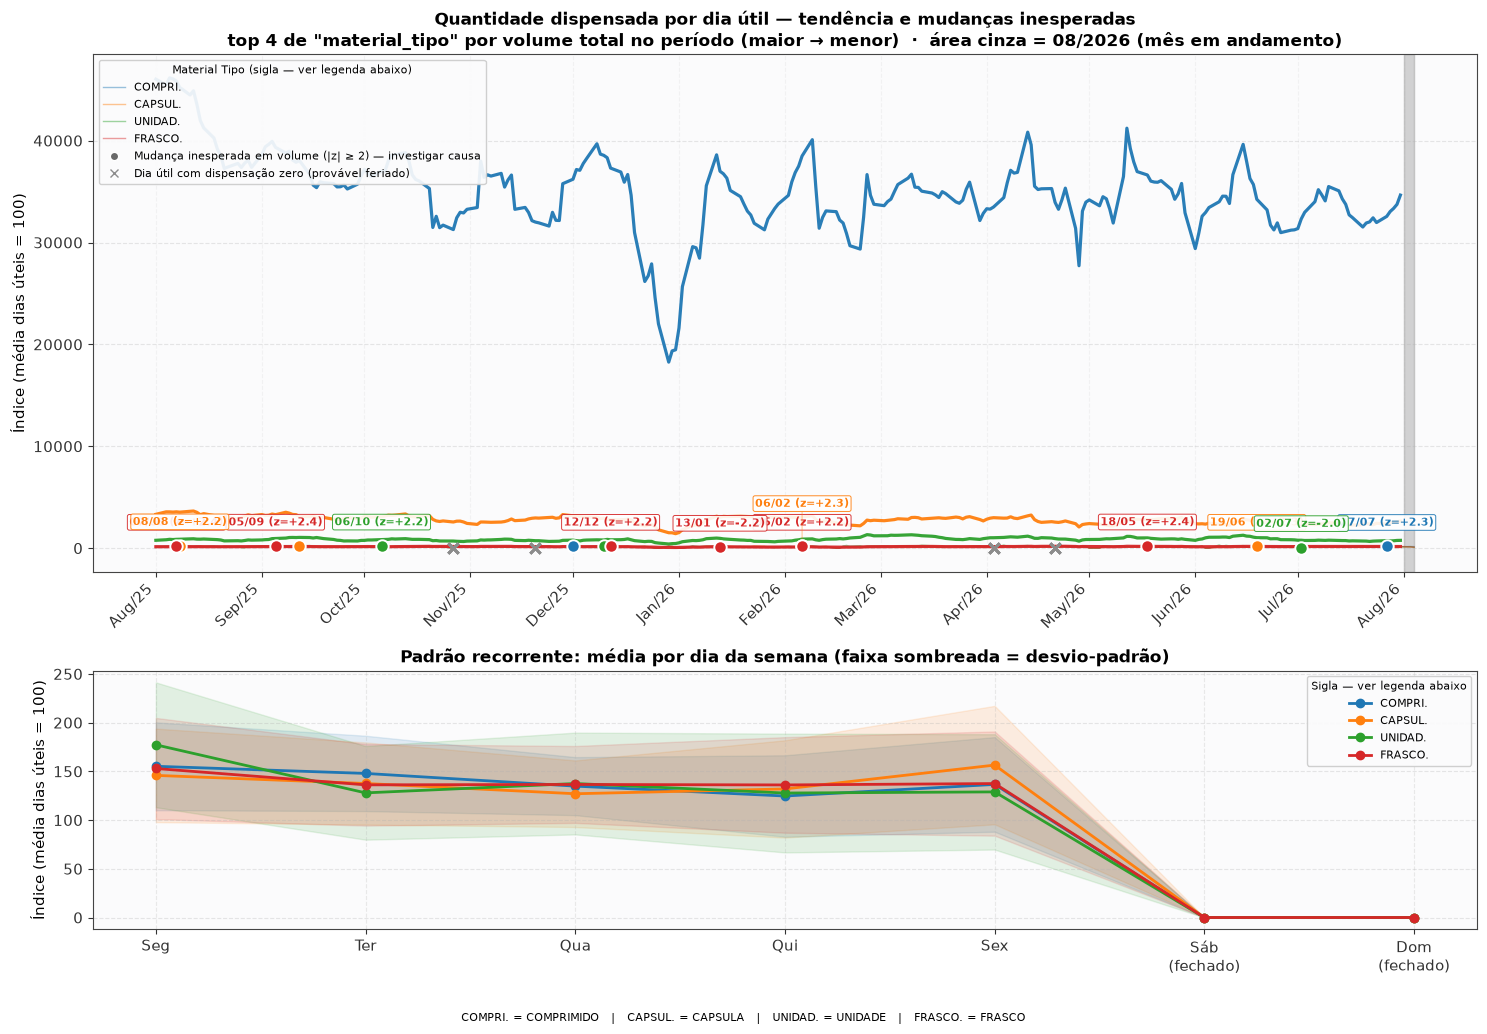

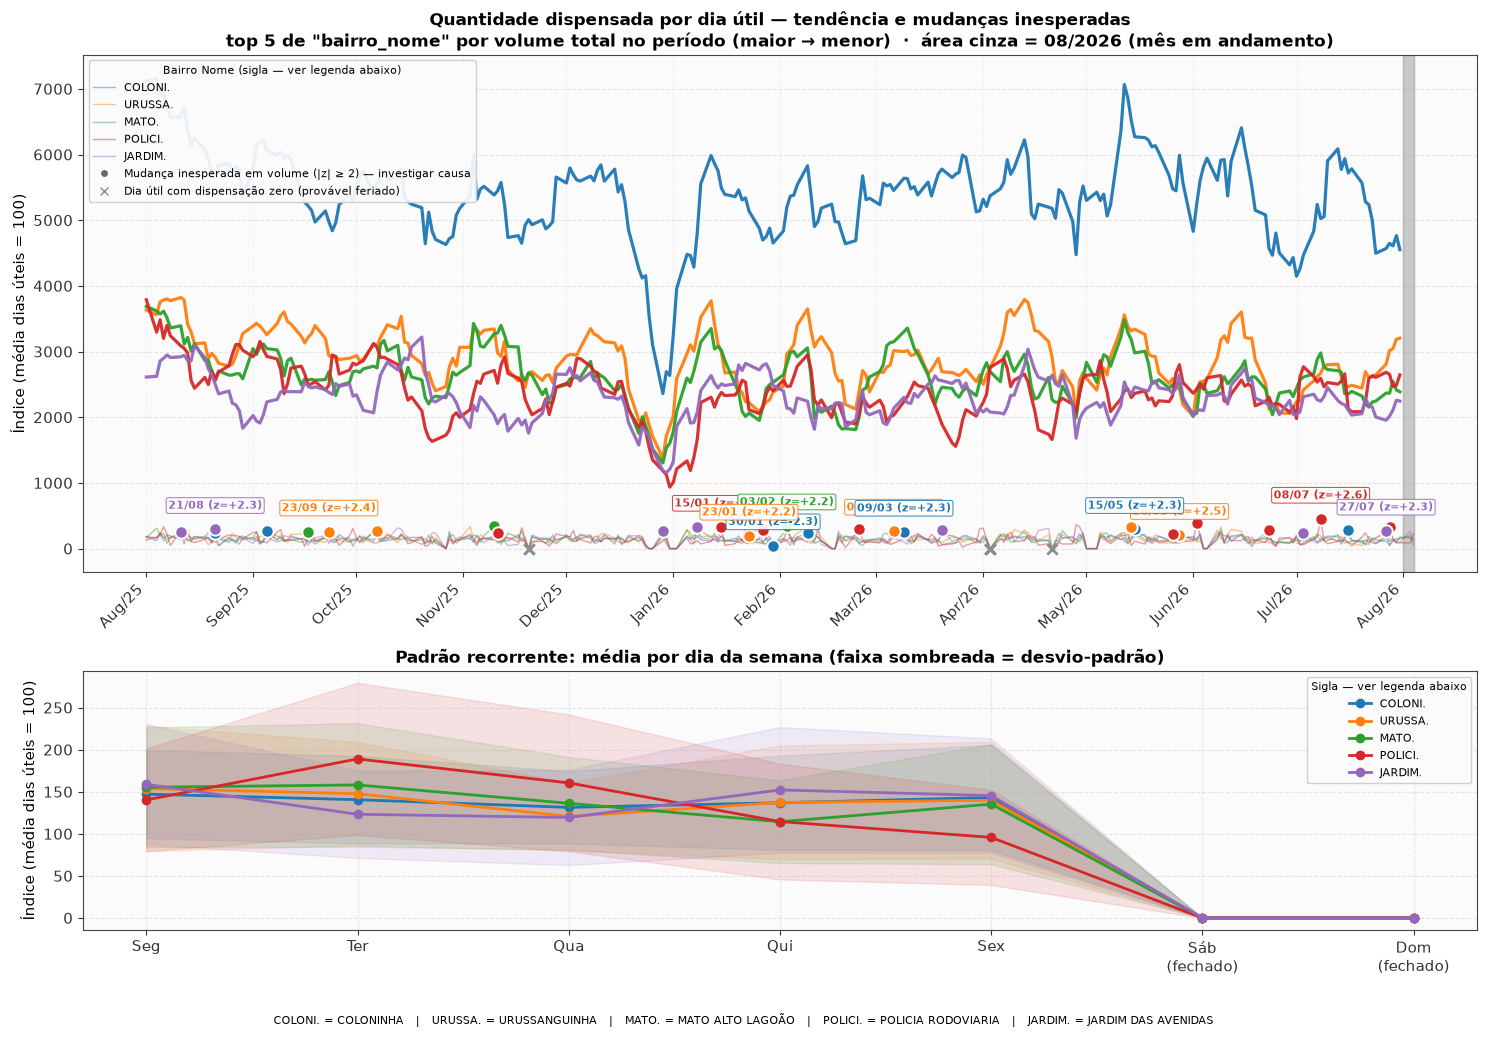

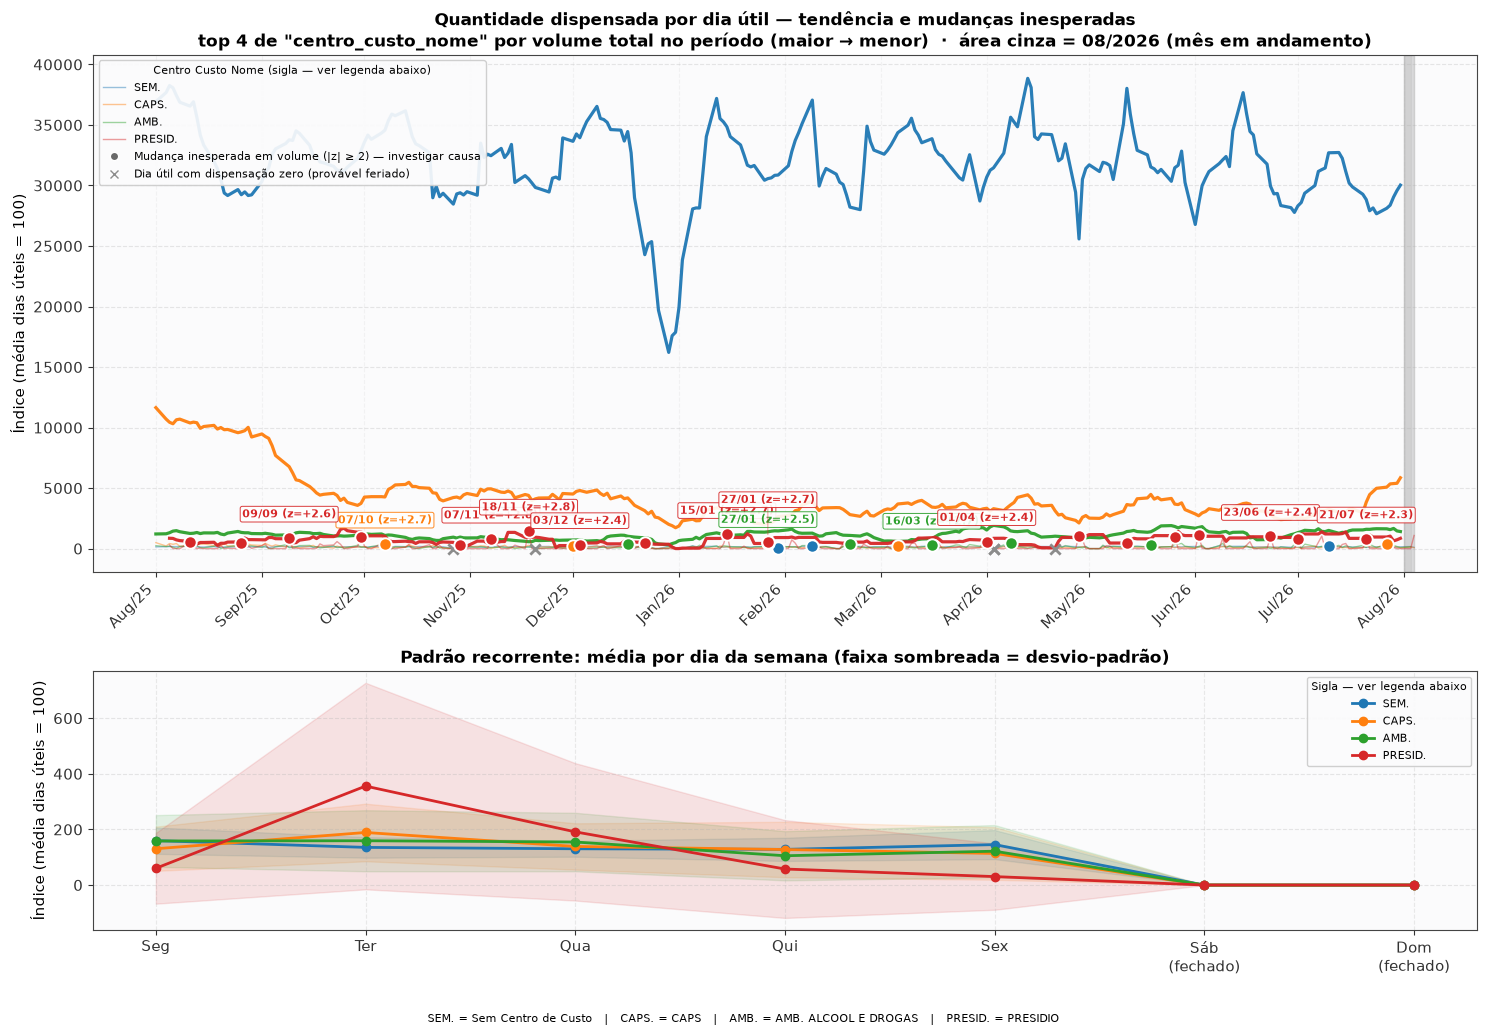

{'Sem Centro de Custo': {'diario':           data  quantidade  dia_semana  quantidade_bruta  parcial  \
  0   2025-08-01  144.234011           4           32749.0    False   
  1   2025-08-02    0.000000           5               0.0    False   
  2   2025-08-03    0.000000           6               0.0    False   
  3   2025-08-04  157.530370           0           35768.0    False   
  4   2025-08-05  172.416656           1           39148.0    False   
  ..         ...         ...         ...               ...      ...   
  364 2026-07-31  151.624303           4           34427.0    False   
  365 2026-08-01    0.000000           5               0.0     True   
  366 2026-08-02    0.000000           6               0.0     True   
  367 2026-08-03  166.655928           0           37840.0     True   
  368 2026-08-04   99.412199           1           22572.0     True   
  
        media_movel    std_movel   z_score anomalia feriado  
  0    36929.000000  2709.783940 -1.542558    Fals

In [7]:
variacao_diaria_coluna(df, 'material_tipo', metodo='indice', n_series=4, mes_parcial=MES_PARCIAL)
variacao_diaria_coluna(df, 'bairro_nome', metodo='indice', n_series=5, mes_parcial=MES_PARCIAL)
variacao_diaria_coluna(df, 'centro_custo_nome', metodo='indice', n_series=4, mes_parcial=MES_PARCIAL)

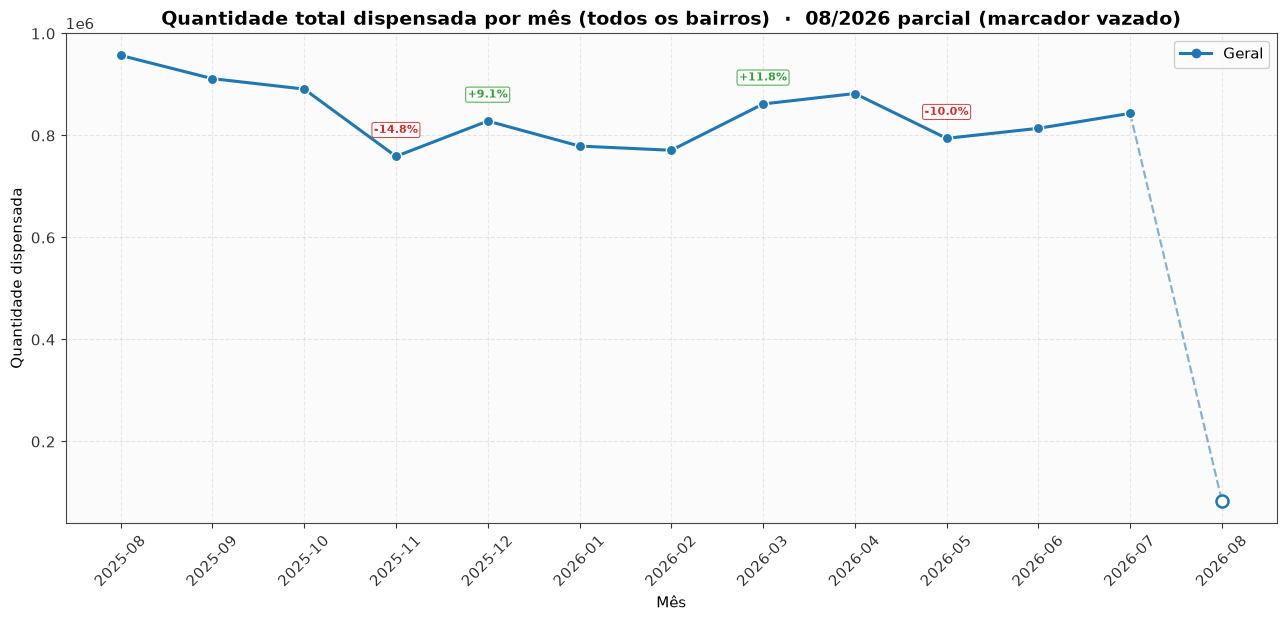

In [8]:
fig, ax = plt.subplots(figsize=(13, 6.5))
anotacoes = []
mensal_geral = plotar_variacao_mensal(df, ax, 'Geral', PALETA[0], metodo='bruto',
                                       lista_anotacoes=anotacoes, mes_parcial=MES_PARCIAL)
anotar_sem_sobreposicao(ax, anotacoes)

titulo = 'Quantidade total dispensada por mês (todos os bairros)'
if MES_PARCIAL is not None:
    titulo += f'  ·  {MES_PARCIAL.strftime("%m/%Y")} parcial (marcador vazado)'
ax.set_title(titulo, fontsize=14, fontweight='bold')
ax.set_xlabel('Mês')
ax.set_ylabel('Quantidade dispensada')
plt.xticks(rotation=45)
ax.grid(axis='y', alpha=0.3)
ax.legend(loc='best')

plt.tight_layout()
plt.savefig('grafico_dispensacao_mensal_geral.png', dpi=150, bbox_inches='tight')
plt.show()

### Como diferentes medicamentos, bairros ou centros de custo se comportam no tempo?

In [9]:
print("Quantidade de Medicamentos Cadastrados........: ", df.groupby("material_nome").ngroups)
print("Quantidade de Bairros Cadastrados.............: ", df.groupby("bairro_nome").ngroups)
print("Quantidade de UPS Cadastrados.................: ", df.groupby("ups_nome").ngroups)
print("Quantidade de Centros Custo Cadastrados.......: ", df.groupby("centro_custo_nome").ngroups)
print("Quantidade de Tipos Cadastrados...............: ", df.groupby("material_tipo").ngroups)
print("Quantidade de Classes Terapêuticas Cadastrados: ", df.groupby("classe_terapeutica").ngroups)

Quantidade de Medicamentos Cadastrados........:  167
Quantidade de Bairros Cadastrados.............:  215
Quantidade de UPS Cadastrados.................:  1
Quantidade de Centros Custo Cadastrados.......:  13
Quantidade de Tipos Cadastrados...............:  8
Quantidade de Classes Terapêuticas Cadastrados:  56


### Dados completos por bairro (não apenas os 5 maiores)

A tabela abaixo lista **todos** os bairros cadastrados, com o total dispensado, a
participação percentual no total geral e o ranking. Se `POPULACAO_BAIRROS` for
preenchido, também mostra a dispensação por 10 mil habitantes -- métrica que evita
que bairros grandes pareçam "consumir mais" só por terem mais moradores.
Diferente dos gráficos de tendência, esta é uma soma simples de todo o período,
então o mês parcial entra normalmente na conta (ele contribui com uma fração real
do total, só não é comparável mês a mês contra meses fechados).

In [10]:
tabela_bairros = tabela_resumo(df, 'bairro_nome')
tabela_bairros

,ranking,bairro_nome,total_dispensado,participacao_%
0,1,COLONINHA,1412274,13.88
1,2,URUSSANGUINHA,756046,7.43
2,3,MATO ALTO LAGOÃO,686288,6.74
3,4,POLICIA RODOVIARIA,629098,6.18
4,5,JARDIM DAS AVENIDAS,608386,5.98
...,...,...,...,...
210,211,PONTAO (HERCILIO LUZ),5,0.00
211,212,JARDIMCIBELE,3,0.00
212,213,LAGOAO--------------------03/13,3,0.00
213,214,SAPIRANGA,3,0.00


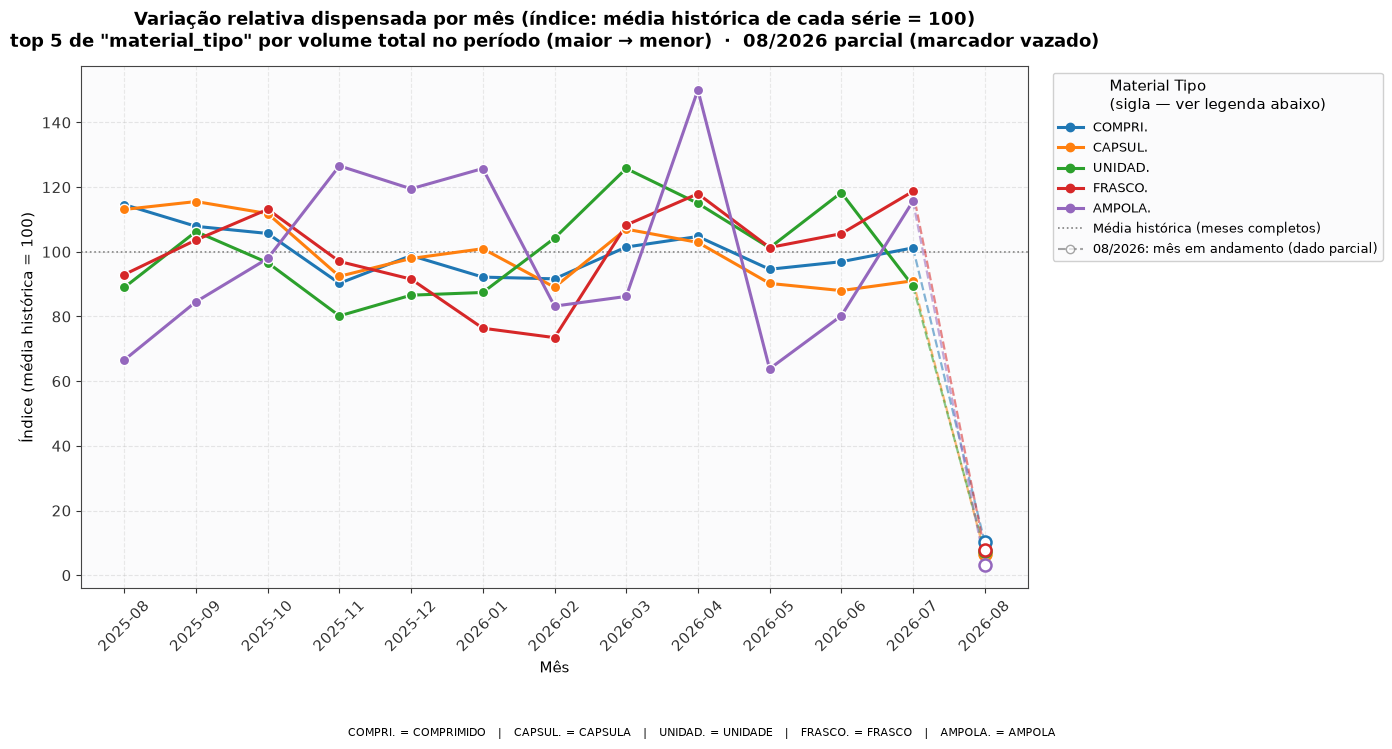

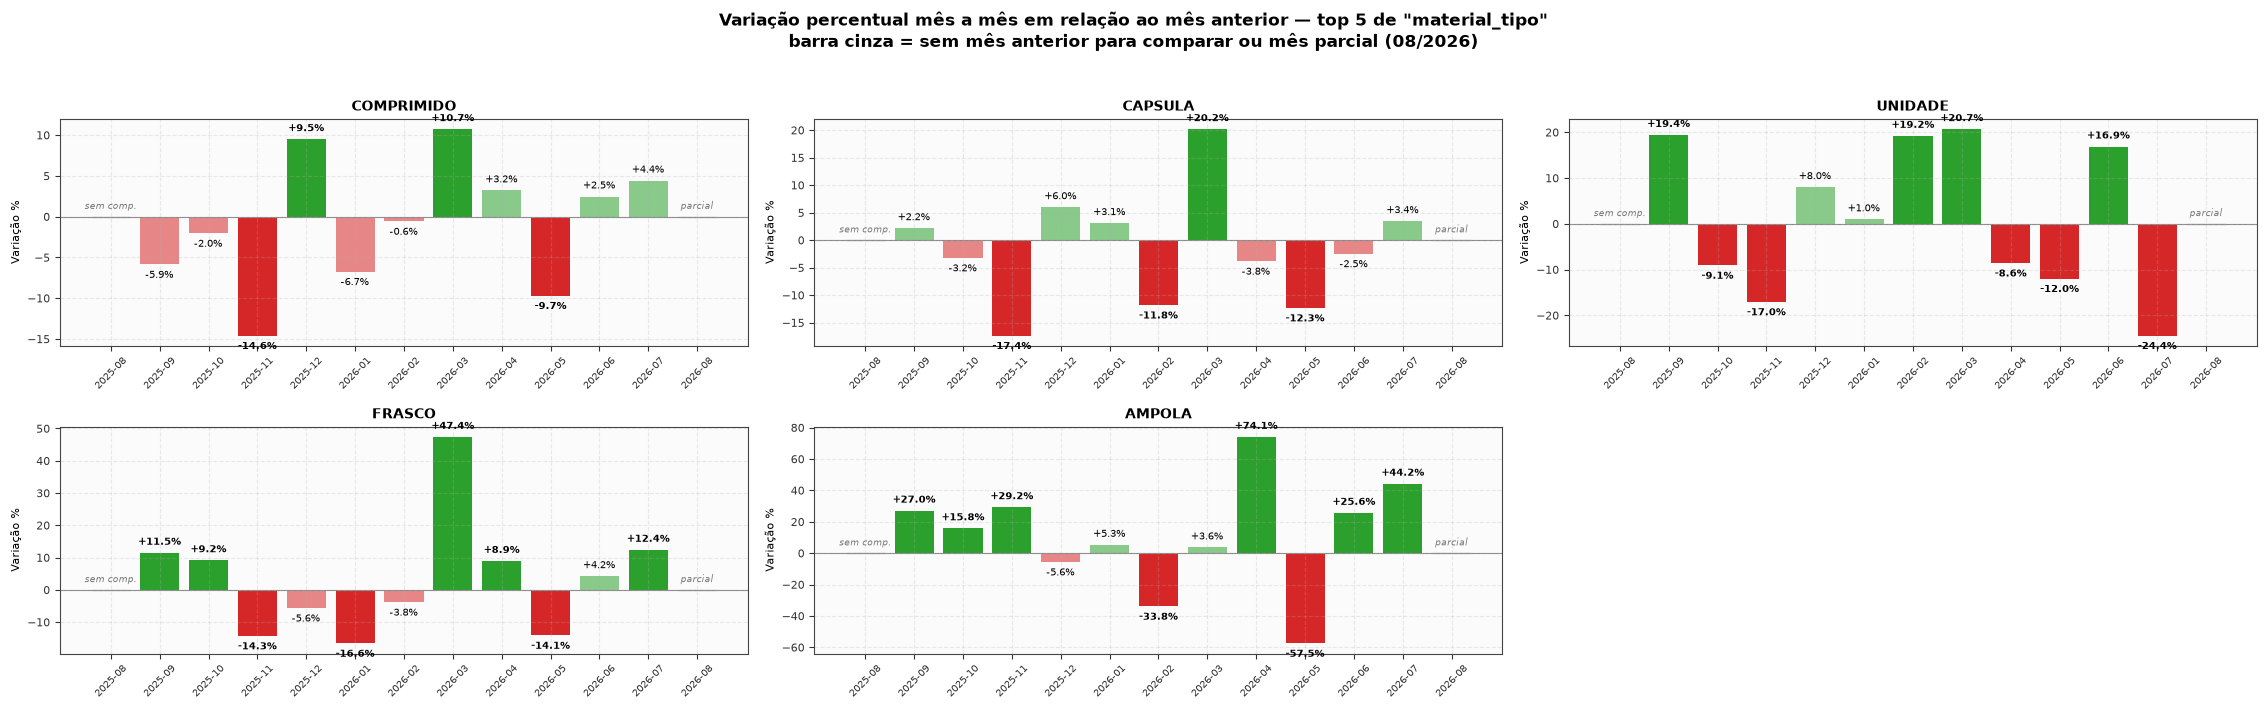

In [11]:
variacao_mensal_coluna(df, 'material_tipo', mes_parcial=MES_PARCIAL)

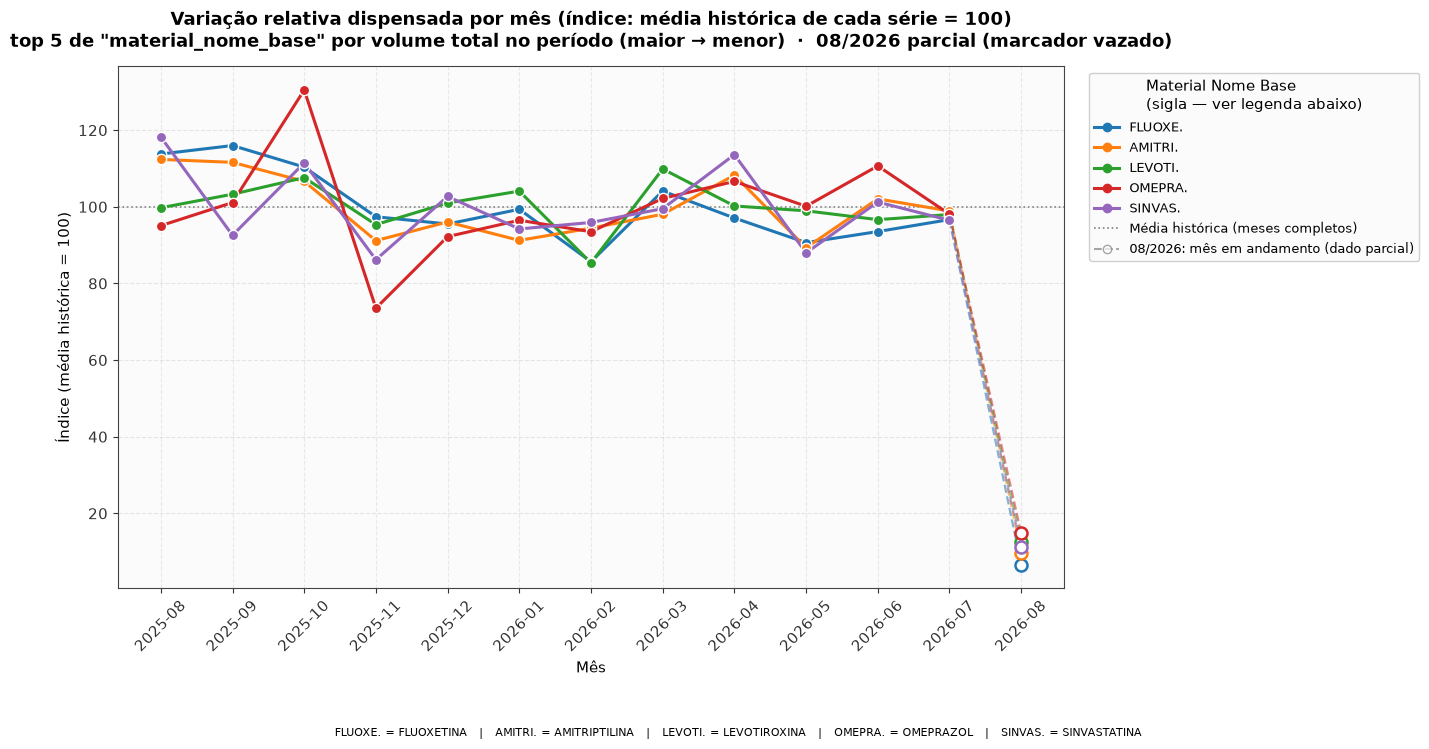

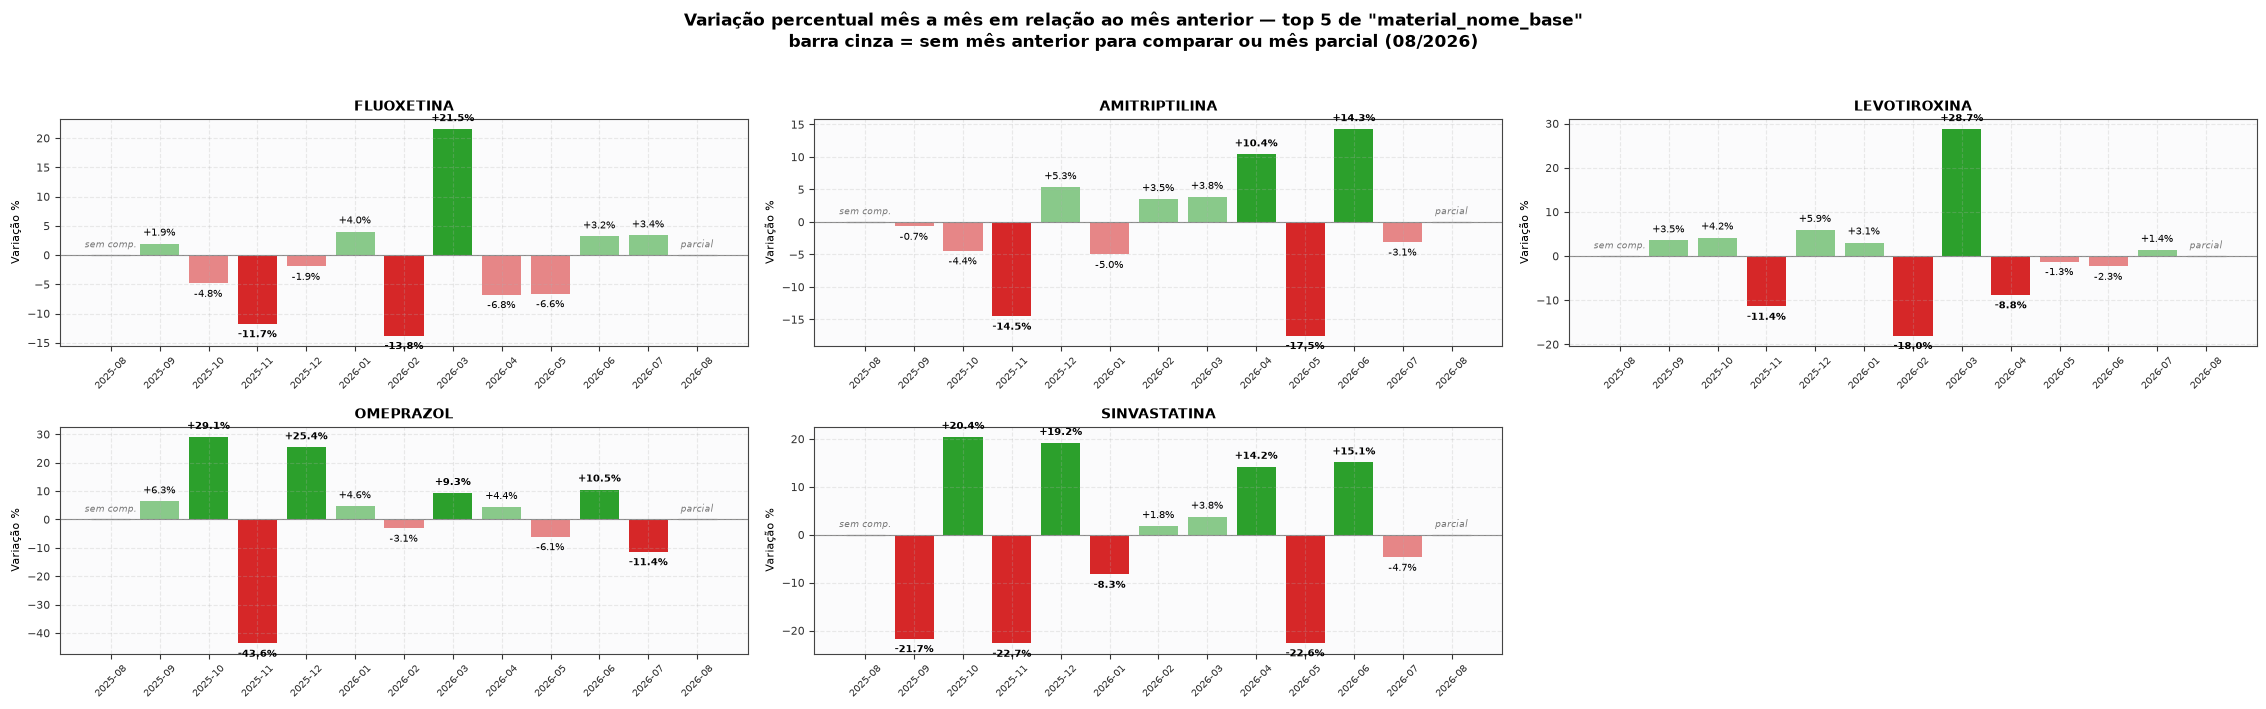

In [12]:
variacao_mensal_coluna(df, 'material_nome_base', mes_parcial=MES_PARCIAL)

### Comparação entre bairros: bruto x normalizado

Primeiro o gráfico bruto (quantidade absoluta), depois o gráfico normalizado por
índice (todos os bairros na mesma escala, base 100 = média histórica de cada um) --
isso evita que a diferença de porte populacional entre bairros distorça a
comparação. Se `POPULACAO_BAIRROS` estiver preenchido, o mesmo pode ser feito com
`metodo='per_capita'` para comparar dispensação real por habitante.

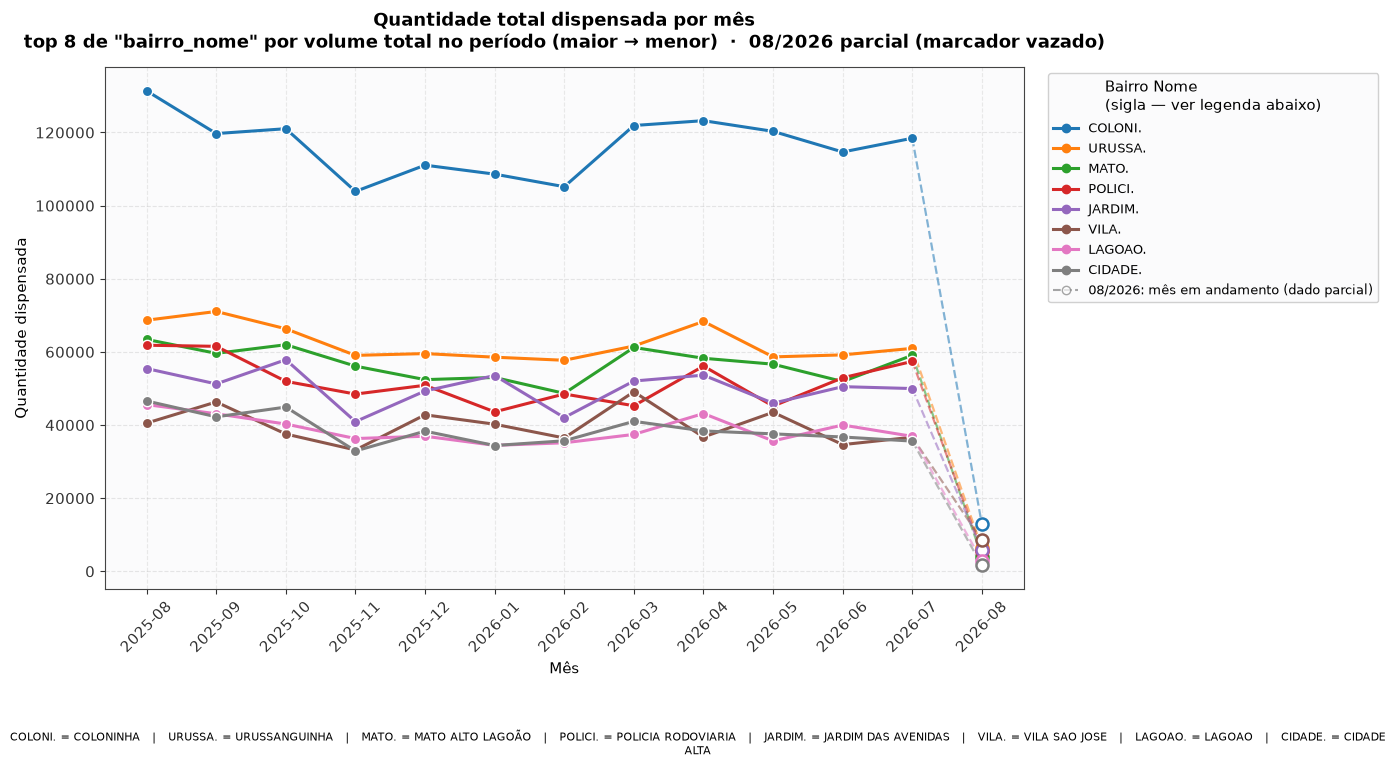

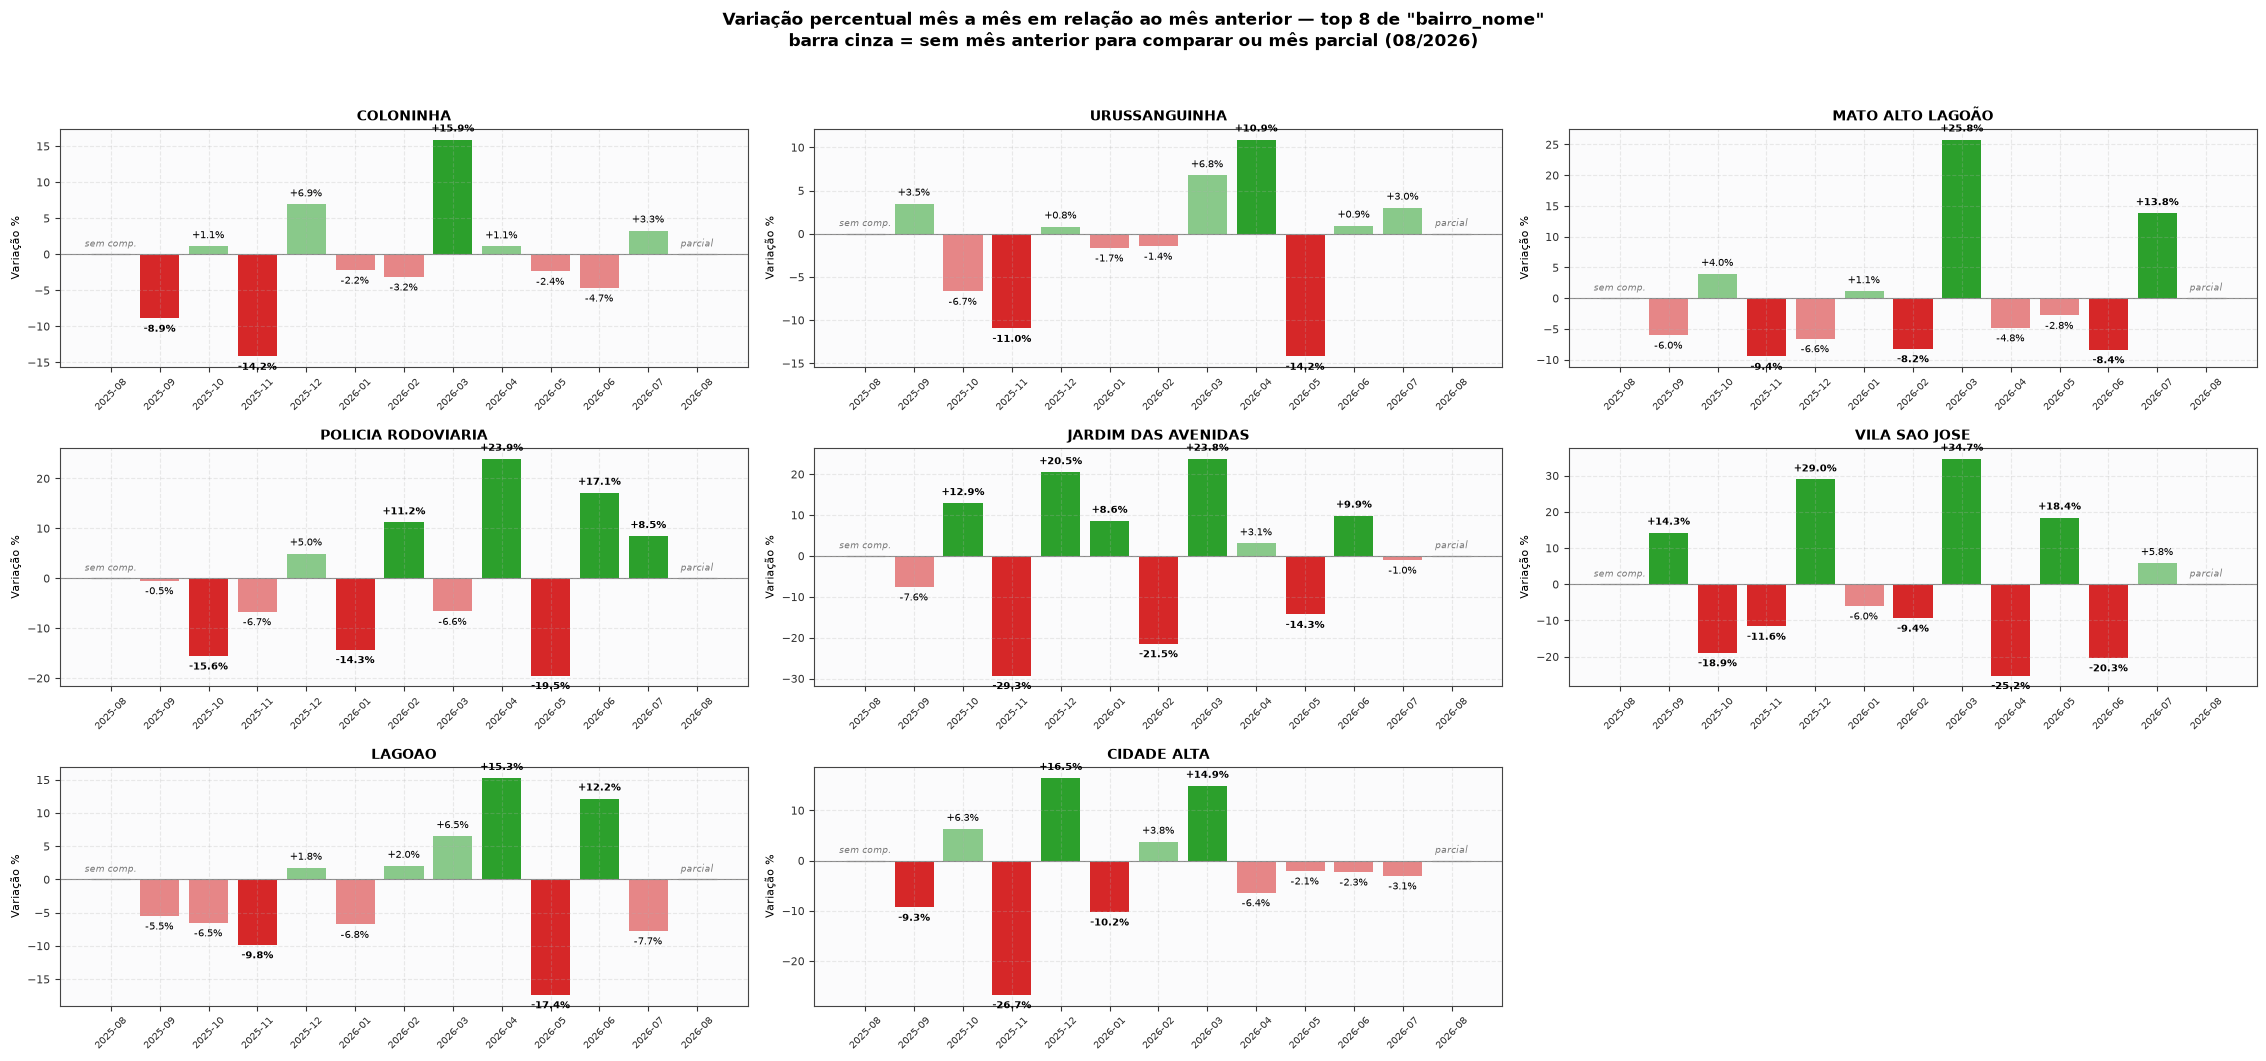

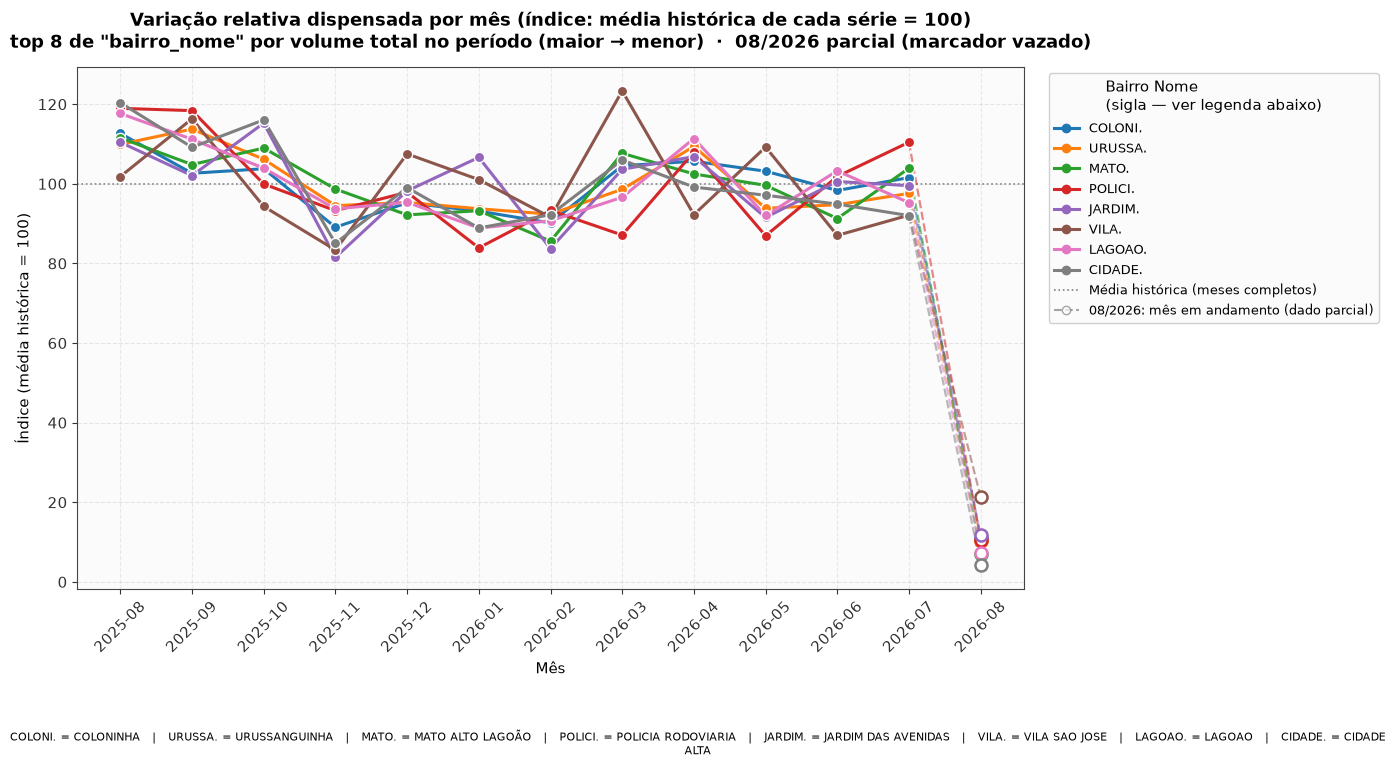

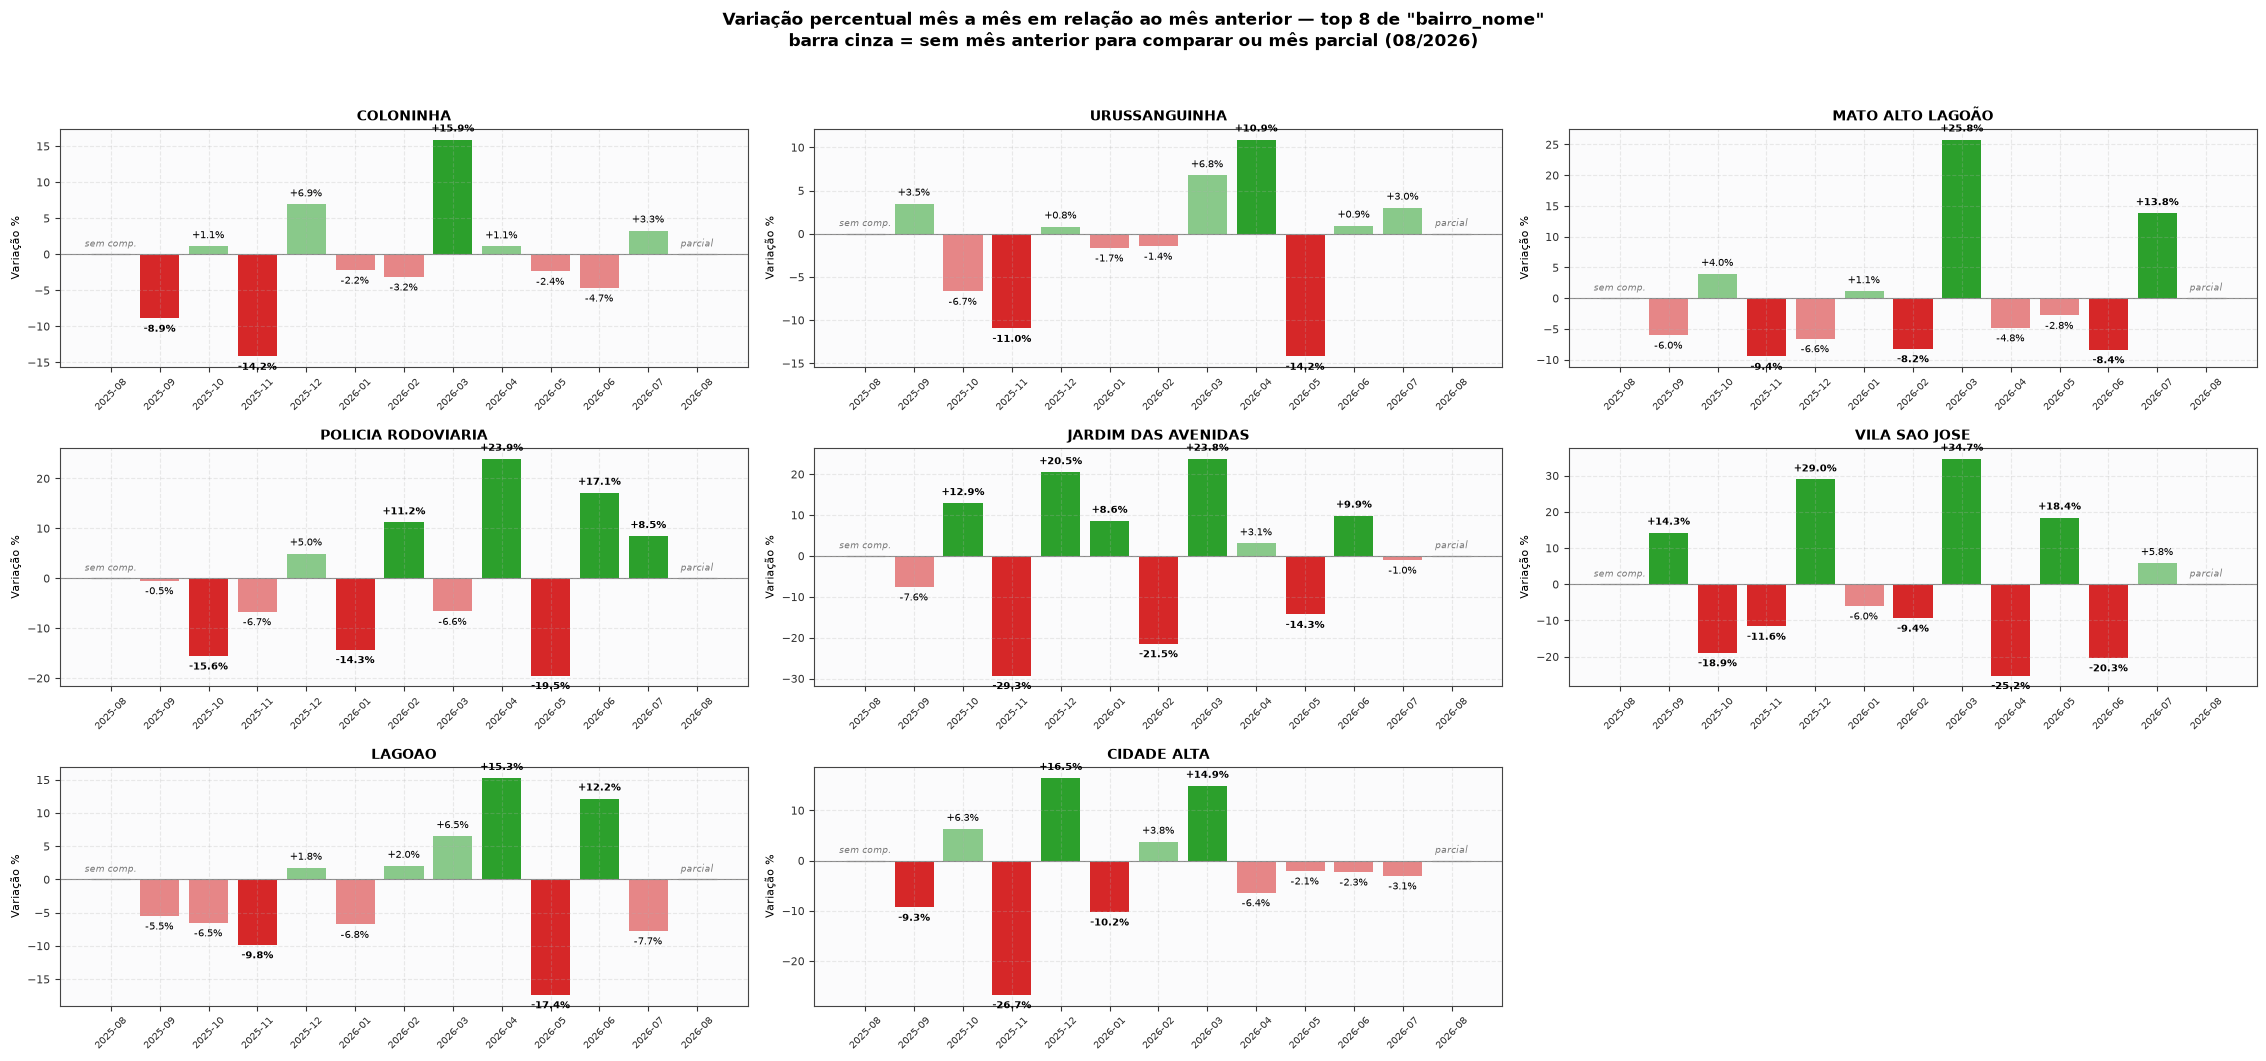

In [13]:
# Volume absoluto (mostra quem dispensa mais em números totais)
variacao_mensal_coluna(df, 'bairro_nome', metodo='bruto', n_series=8, mes_parcial=MES_PARCIAL)

# Normalizado por índice (compara a TENDÊNCIA dos bairros na mesma escala,
# sem que bairros maiores dominem visualmente o gráfico)
variacao_mensal_coluna(df, 'bairro_nome', metodo='indice', n_series=8, mes_parcial=MES_PARCIAL)

# Se POPULACAO_BAIRROS estiver preenchido, descomente para comparar por habitante:
# variacao_mensal_coluna(df, 'bairro_nome', metodo='per_capita', populacao=POPULACAO_BAIRROS, n_series=8, mes_parcial=MES_PARCIAL)

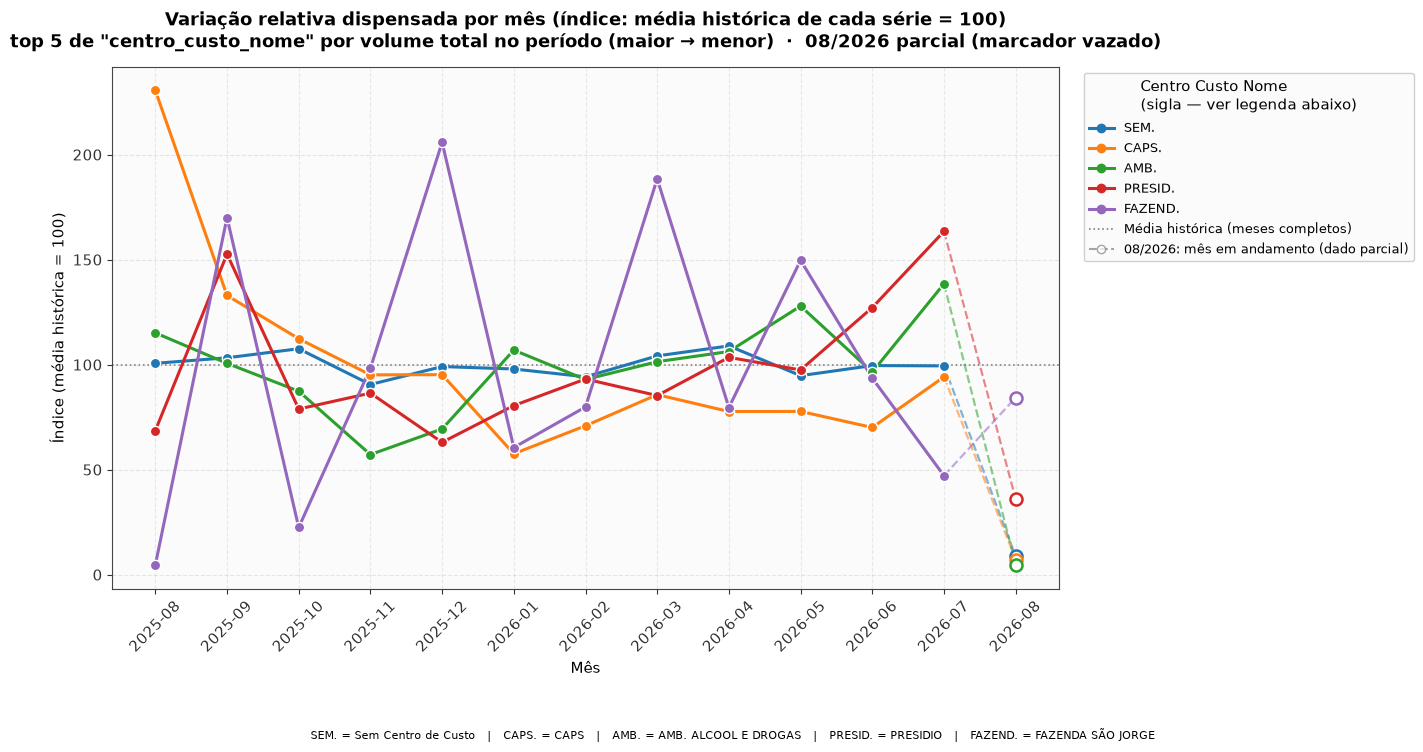

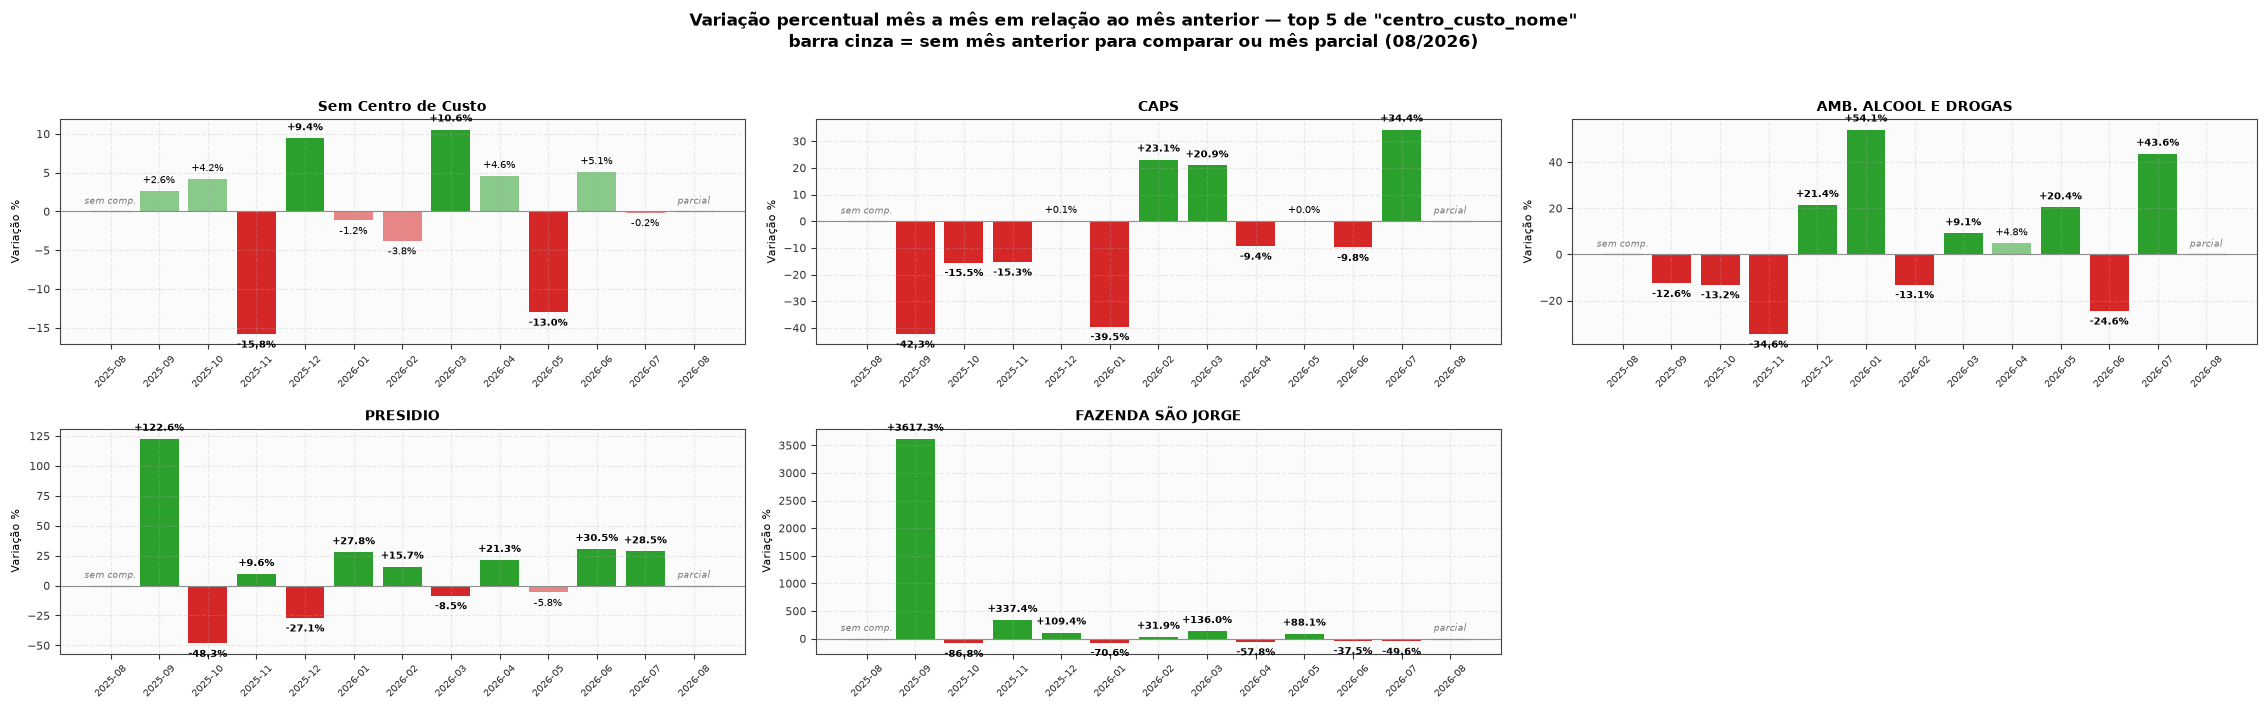

In [14]:
variacao_mensal_coluna(df, 'centro_custo_nome', mes_parcial=MES_PARCIAL)

### Hipótese a investigar: por que os antidepressivos concentram tanta variação?

**O que os dados mostram (evidência):** antidepressivos, anticonvulsivantes e
analgésicos não narcóticos são as três classes terapêuticas de maior volume no
período, e antidepressivos é a classe com maior amplitude de variação mês a mês
(ver gráfico abaixo).

**Hipótese que ainda precisa de outros dados para ser confirmada:** não é
possível, só com este arquivo, afirmar *por que* essa classe varia tanto. Uma
hipótese plausível é que ela reflita mudanças na demanda por saúde mental na
região; outra é que reflita mudanças no fornecimento/compra do próprio
medicamento (estoque, licitação, protocolo de prescrição). Confirmar qualquer
uma dessas explicações exigiria cruzar este arquivo com outra fonte -- por
exemplo, dados de atendimento em saúde mental, registro de entrada de estoque,
ou mudanças de protocolo clínico no período. **Vale destacar que não há, nesta
base, nenhuma informação sobre causa de óbito ou diagnóstico**, então qualquer
afirmação que ligue o consumo de um medicamento a uma causa de morte específica
não pode ser sustentada pelos dados aqui disponíveis -- fica registrada apenas
como pergunta para investigação futura, não como conclusão.

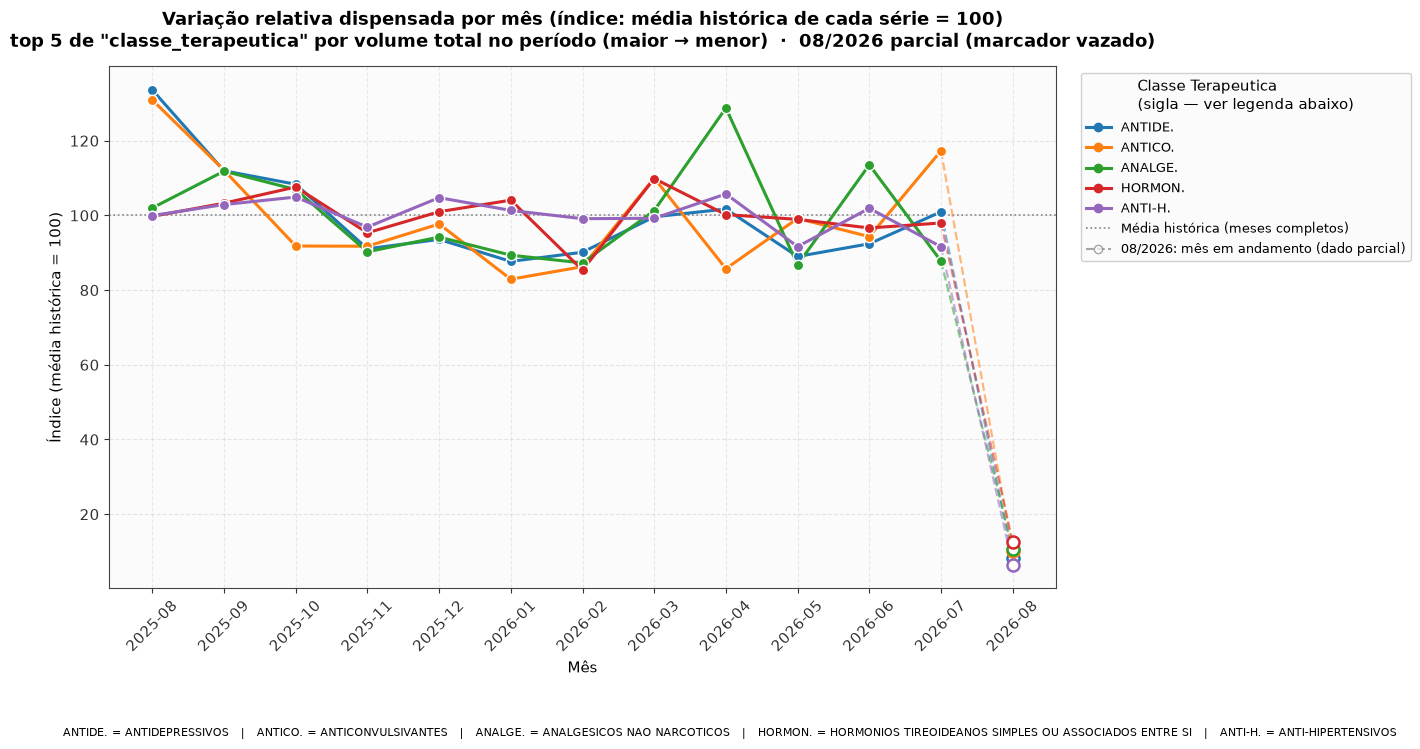

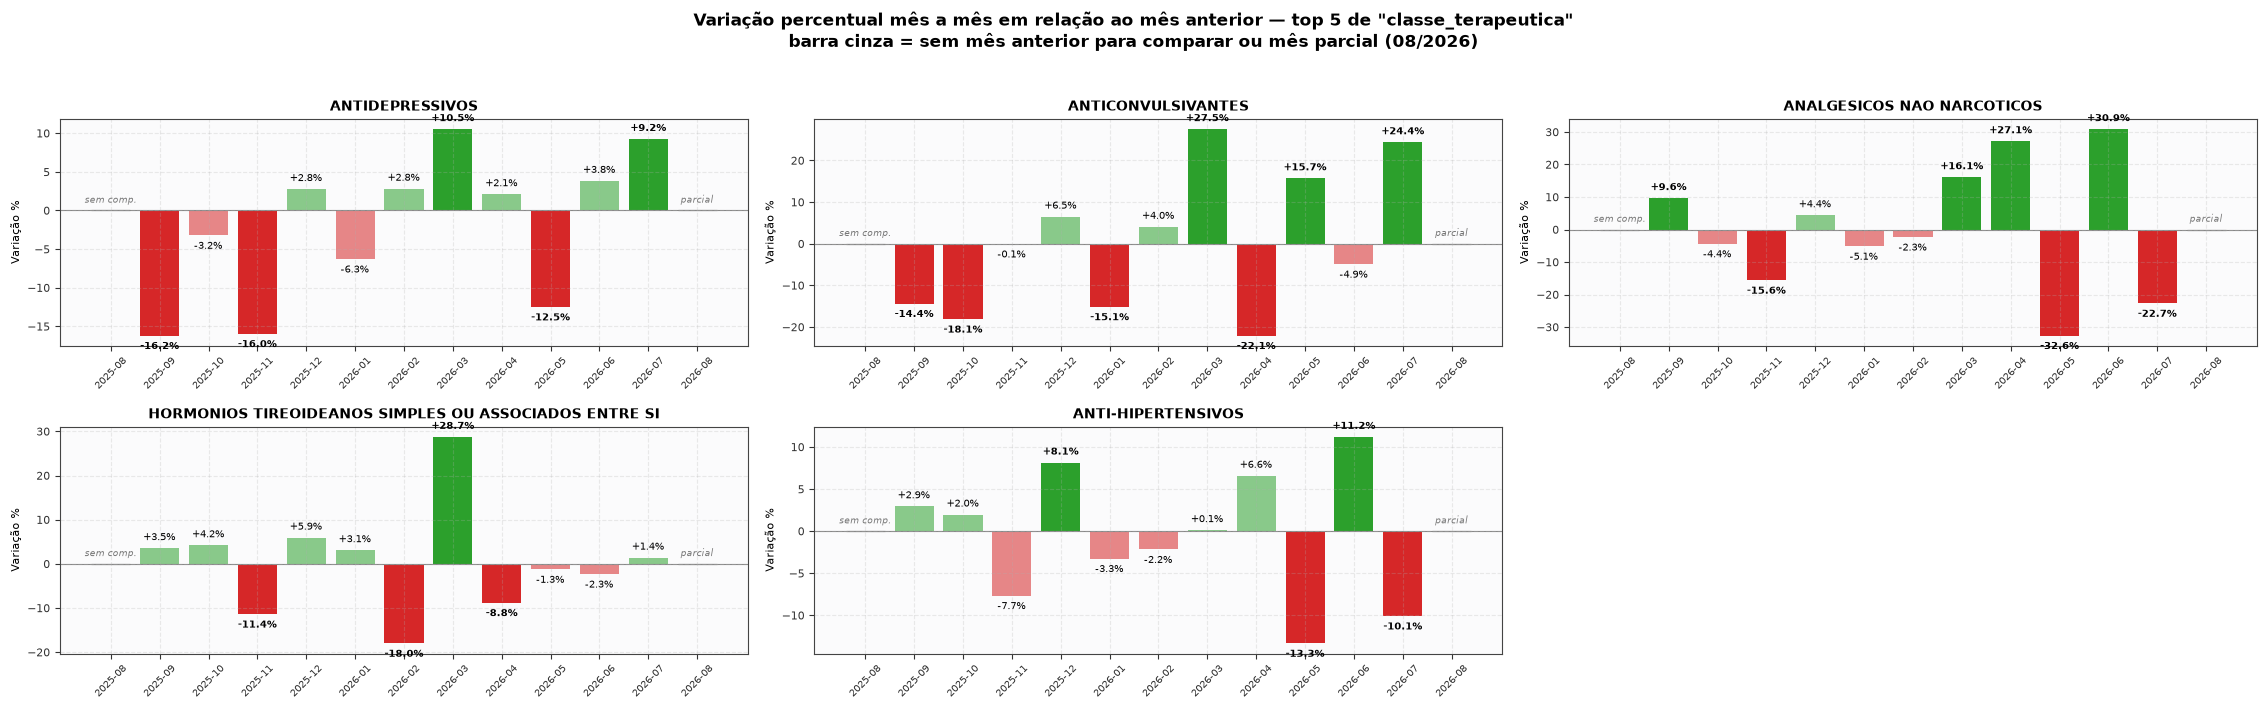

In [15]:
variacao_mensal_coluna(df, 'classe_terapeutica', mes_parcial=MES_PARCIAL)

Top 5 classes terapêuticas (volume total nos meses completos do período):
classe_terapeutica
ANTIDEPRESSIVOS                                          1958229
ANTICONVULSIVANTES                                        894189
ANALGESICOS NAO NARCOTICOS                                771756
HORMONIOS TIREOIDEANOS SIMPLES OU ASSOCIADOS ENTRE SI     576914
ANTI-HIPERTENSIVOS                                        489434


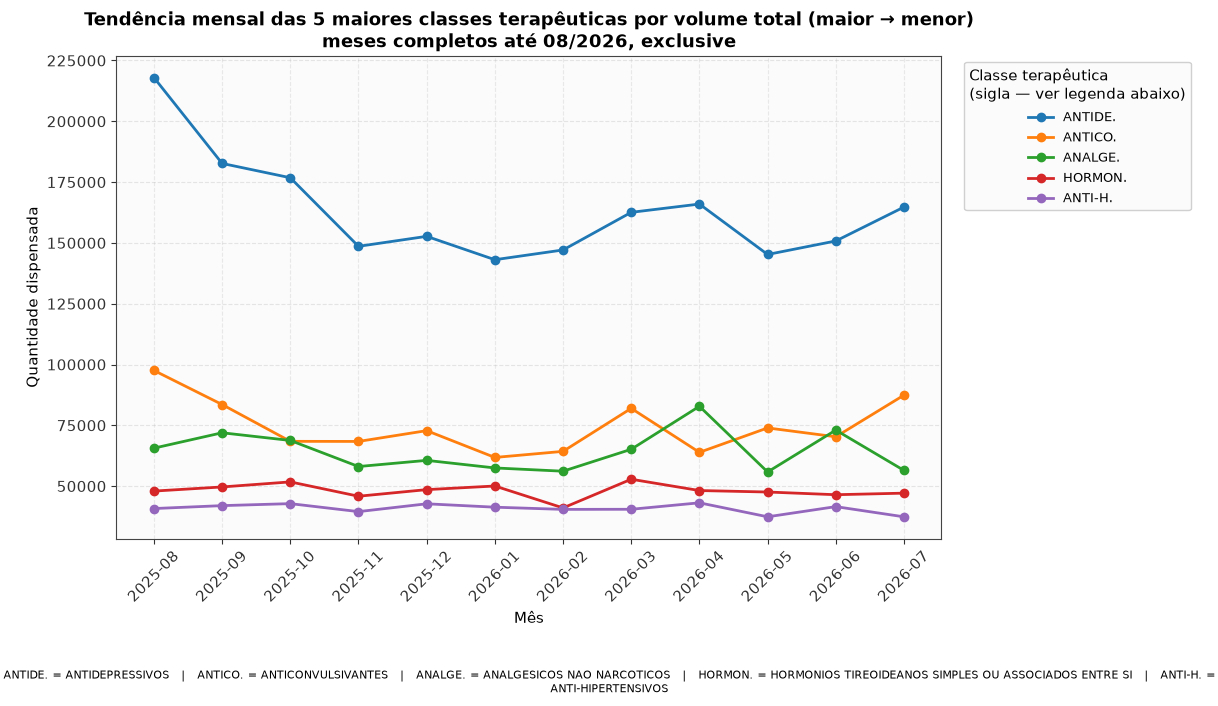

classe_terapeutica,ANTIDEPRESSIVOS,ANTICONVULSIVANTES,ANALGESICOS NAO NARCOTICOS,HORMONIOS TIREOIDEANOS SIMPLES OU ASSOCIADOS ENTRE SI,ANTI-HIPERTENSIVOS
ano_mes_str,,,,,
2025-08,217985,97552,65601,47950,40770
2025-09,182675,83538,71929,49650,41970
2025-10,176790,68409,68768,51730,42790
2025-11,148590,68365,58046,45837,39510
2025-12,152695,72804,60581,48550,42724
2026-01,143085,61785,57466,50040,41330
2026-02,147095,64283,56126,41030,40428
2026-03,162570,81968,65141,52820,40472
2026-04,165972,63886,82814,48175,43130


In [16]:
# Usa os mesmos meses considerados "completos" no restante do notebook
# (reaproveita MES_PARCIAL, já identificado, em vez de um novo critério ad hoc)
df['ano_mes'] = df['data'].dt.to_period('M')
df_full = df[df['ano_mes'] != MES_PARCIAL].copy() if MES_PARCIAL is not None else df.copy()
df_full['ano_mes_str'] = df_full['ano_mes'].astype(str)

# Top 5 classes terapêuticas por volume total dispensado no período (meses completos)
top5 = (
    df_full.groupby('classe_terapeutica')['quantidade']
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

print("Top 5 classes terapêuticas (volume total nos meses completos do período):")
print(top5.to_string())

# Série mensal de cada uma das 5 classes
pivot = (
    df_full[df_full['classe_terapeutica'].isin(top5.index)]
    .groupby(['ano_mes_str', 'classe_terapeutica'])['quantidade']
    .sum()
    .unstack()[top5.index]
)

# Abreviações curtas para a legenda (mesma função usada nos outros gráficos)
abreviacoes = gerar_abreviacoes(top5.index)

# Plotar tendência mensal das 5 maiores classes terapêuticas
fig, ax = plt.subplots(figsize=(12, 6.5))
for col in pivot.columns:
    ax.plot(pivot.index, pivot[col], marker='o', linewidth=2, label=abreviacoes[col])

titulo = 'Tendência mensal das 5 maiores classes terapêuticas por volume total (maior → menor)'
if MES_PARCIAL is not None:
    titulo += f'\nmeses completos até {MES_PARCIAL.strftime("%m/%Y")}, exclusive'
ax.set_title(titulo, fontsize=13, fontweight='bold')
ax.set_xlabel('Mês')
ax.set_ylabel('Quantidade dispensada')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9,
          title='Classe terapêutica\n(sigla — ver legenda abaixo)')
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=45)

fig.text(0.5, -0.04, texto_legenda_abreviada(abreviacoes), ha='center', va='top', fontsize=8, wrap=True)

plt.tight_layout()
plt.savefig('grafico_top5_classes_terapeuticas.png', dpi=150, bbox_inches='tight')
plt.show()

pivot.round(0)

## 4. Visão geral da rede: tendência e mudanças inesperadas

Este gráfico reaproveita as mesmas funções usadas nos recortes por bairro/tipo/
centro de custo, mas aplicadas ao **total da rede** (todos os bairros e
medicamentos somados) -- assim, os mesmos critérios de mês parcial, anomalia e
padrão semanal usados no resto do notebook valem aqui também, sem duplicar
lógica em outra célula.

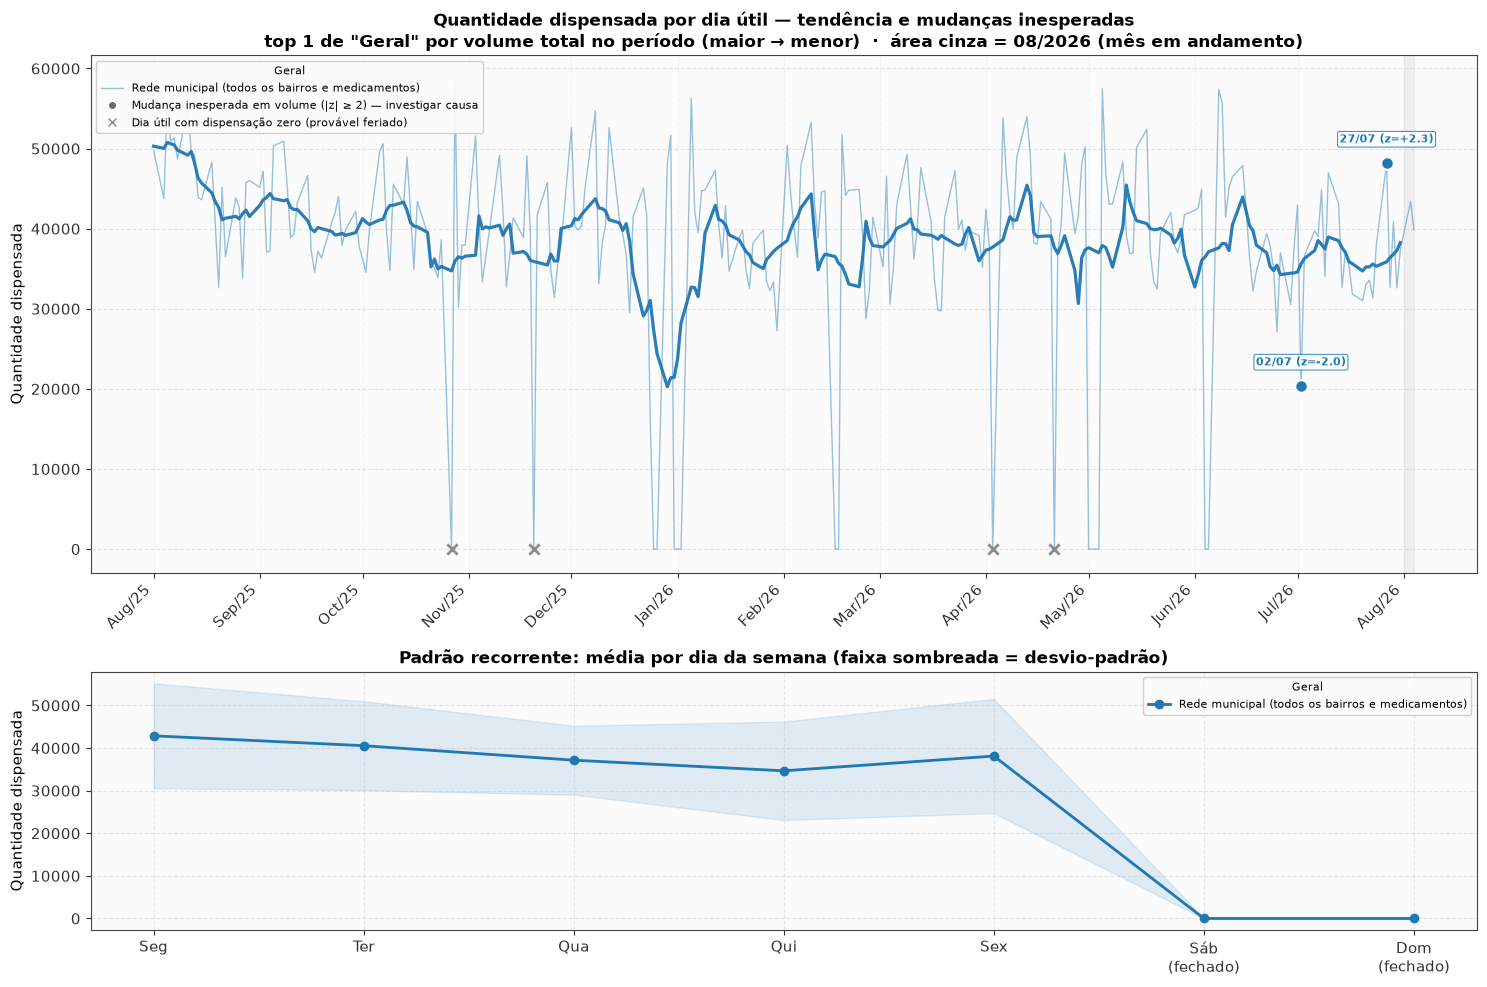

=== PADRÃO RECORRENTE (dia da semana), total da rede ===
dia_semana
Seg    42871.4
Ter    40555.3
Qua    37154.1
Qui    34659.0
Sex    38120.9
Sáb        0.0
Dom        0.0
-> Entre os dias úteis, a dispensação é sistematicamente menor em Qui e maior em Seg. Sáb/Dom não abrem (dispensação estrutural = 0).

=== DIAS ÚTEIS COM DISPENSAÇÃO ZERO (prováveis feriados) ===
      data
27/10/2025
20/11/2025
03/04/2026
21/04/2026

=== MUDANÇAS INESPERADAS EM VOLUME (|z-score| >= 2.0, farmácia aberta) ===
      data  quantidade_bruta  media_movel  z_score
02/07/2026           20354.0      35579.2     -2.0
27/07/2026           48184.0      35856.2      2.3


In [17]:
# Cria uma coluna constante para reaproveitar as funções de gráfico/anomalia
# no conjunto INTEIRO da base, sem separar por bairro, medicamento etc.
NOME_GERAL = 'Rede municipal (todos os bairros e medicamentos)'
df_geral = df.copy()
df_geral['Geral'] = NOME_GERAL

resultado_geral = variacao_diaria_coluna(df_geral, 'Geral', metodo='bruto', n_series=1,
                                          mes_parcial=MES_PARCIAL)[NOME_GERAL]

diario_geral = resultado_geral['diario']
padrao_semanal_geral = resultado_geral['padrao_semanal']
anomalias_volume_geral = resultado_geral['anomalias_volume']
feriados_geral = resultado_geral['feriados']

nomes_dias = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']

print("=== PADRÃO RECORRENTE (dia da semana), total da rede ===")
print(padrao_semanal_geral.round(1).rename(index=dict(enumerate(nomes_dias))).to_string())
dia_min = nomes_dias[padrao_semanal_geral.iloc[:5].idxmin()]
dia_max = nomes_dias[padrao_semanal_geral.iloc[:5].idxmax()]
print(f"-> Entre os dias úteis, a dispensação é sistematicamente menor em {dia_min} "
      f"e maior em {dia_max}. Sáb/Dom não abrem (dispensação estrutural = 0).")

print("\n=== DIAS ÚTEIS COM DISPENSAÇÃO ZERO (prováveis feriados) ===")
if len(feriados_geral):
    tabela_f = feriados_geral[['data']].copy()
    tabela_f['data'] = tabela_f['data'].dt.strftime('%d/%m/%Y')
    print(tabela_f.to_string(index=False))
else:
    print("Nenhum dia útil com dispensação zero foi encontrado.")

print("\n=== MUDANÇAS INESPERADAS EM VOLUME (|z-score| >= 2.0, farmácia aberta) ===")
if len(anomalias_volume_geral):
    tabela = anomalias_volume_geral[['data', 'quantidade_bruta', 'media_movel', 'z_score']].copy()
    tabela['data'] = tabela['data'].dt.strftime('%d/%m/%Y')
    tabela[['quantidade_bruta', 'media_movel', 'z_score']] = tabela[['quantidade_bruta', 'media_movel', 'z_score']].round(1)
    print(tabela.to_string(index=False))
else:
    print("Nenhum dia fora do padrão esperado foi encontrado.")

### Como ler o z-score (o número por trás dos pontos marcados como anomalia)

**Cálculo:** `z = (quantidade do dia − média móvel local) / desvio-padrão local`,
calculado numa janela de 10 dias úteis ao redor de cada dia.

* `z = 0` → o dia foi igual à média dos dias ao redor (comportamento normal).
* `z = +2` → dispensação 2 desvios-padrão **acima** da média local (bem mais alto que o normal na região).
* `z = -2` → dispensação 2 desvios-padrão **abaixo** da média local (bem mais baixo que o normal na região).

Um `|z| >= 2` significa que o valor do dia se destaca **estatisticamente** em
relação à vizinhança dele -- não é uma impressão visual, é uma medida relativa ao
comportamento local da série (por isso um mesmo valor absoluto pode ser normal
em um período e anômalo em outro).

**Evidência vs. hipótese:** dias úteis com dispensação **zero** têm explicação
objetiva e verificável (calendário de feriados municipais/estaduais/nacionais) --
isso é evidência, não hipótese. Já os dias marcados como "mudança inesperada em
**volume**" (farmácia aberta, mas número fora do padrão) não têm causa conhecida
apenas com este arquivo: podem refletir, por exemplo, falha pontual de sistema,
falta de algum item em estoque, ou acúmulo de pedidos represados. Sem cruzar com
outra fonte (logs do sistema, registro de estoque, escala de atendimento), essas
explicações continuam sendo **hipóteses**, não conclusões.

## 5. Limitação importante: um único ciclo anual na base

Como a base cobre pouco mais de um ano, **não é possível comparar o mesmo mês
entre anos diferentes** (por exemplo, "julho/2025 contra julho/2026") para
confirmar se um padrão sazonal se repete de fato ano após ano, ou se foi um
evento pontual daquele ano específico. Por isso, os padrões sazonais discutidos
aqui (ex.: aumento no inverno) são tratados como **indício**, reforçado quando
aparece de forma consistente em mais de um recorte (ex.: mesmo padrão em
bairros diferentes), e não como um ciclo comprovado -- confirmar isso exigiria
uma base com pelo menos 2 a 3 anos completos.

## 6. Relatório geral

Os números abaixo **não são digitados à mão**: são gerados por código a partir
das mesmas tabelas (`mensal_geral`, `diario_geral`, `padrao_semanal_geral`,
`anomalias_volume_geral`, `feriados_geral`) calculadas nas seções anteriores.
Rodar esta célula depois de atualizar o CSV atualiza o relatório automaticamente
e mantém os números sempre conferíveis com os dados preparados.

In [18]:
# --- 1. Variações mensais relevantes (>= 8%, excluindo o mês parcial) ---
variacoes_relevantes = mensal_geral[mensal_geral['relevante']].copy()
linhas_variacao = []
for _, row in variacoes_relevantes.iterrows():
    sinal = 'Aumento' if row['variacao_pct'] > 0 else 'Redução'
    linhas_variacao.append(
        f"* **{row['ano_mes_str']}**: {sinal} de {abs(row['variacao_pct']):.1f}% "
        f"em relação ao mês anterior (de {row['quantidade_bruta'] / (1 + row['variacao_pct']/100):,.0f} "
        f"para {row['quantidade_bruta']:,.0f} unidades)."
    )
texto_variacoes = "\n".join(linhas_variacao) if linhas_variacao else "* Nenhuma variação mês a mês acima de 8% foi encontrada nos meses completos."

# --- 2. Médias semanais (dias úteis + fim de semana fechado) ---
linhas_semana = []
for i, nome in enumerate(nomes_dias):
    valor = padrao_semanal_geral.iloc[i]
    if i < 5:
        linhas_semana.append(f"* {nome}: {valor:,.0f}")
    else:
        linhas_semana.append(f"* {nome}: 0,00 (farmácias fechadas)")
texto_semana = "\n".join(linhas_semana)

dia_maior = nomes_dias[padrao_semanal_geral.iloc[:5].idxmax()]
dia_menor = nomes_dias[padrao_semanal_geral.iloc[:5].idxmin()]

# --- 3. Dias com mudanças inesperadas em volume (não-feriado) ---
linhas_anomalias = []
for _, row in anomalias_volume_geral.iterrows():
    linhas_anomalias.append(
        f"* **{row['data'].strftime('%d/%m/%Y')}**: quantidade dispensada = {row['quantidade_bruta']:,.0f} "
        f"(média local ~{row['media_movel']:,.0f}, z = {row['z_score']:+.1f})."
    )
texto_anomalias = "\n".join(linhas_anomalias) if linhas_anomalias else "* Nenhum dia com mudança inesperada de volume foi encontrado."

# --- 4. Dias úteis com dispensação zero (prováveis feriados) ---
lista_feriados = ", ".join(d.strftime('%d/%m/%Y') for d in feriados_geral['data']) if len(feriados_geral) else "nenhum"

# --- 5. Nota sobre o mês parcial, se houver ---
if MES_PARCIAL is not None:
    dias_no_mes_parcial = df.loc[df['data'].dt.to_period('M') == MES_PARCIAL, 'data'].dt.normalize().nunique()
    nota_parcial = (
        f"\n> ⚠️ **Período parcial identificado:** {MES_PARCIAL.strftime('%m/%Y')} tem apenas "
        f"{dias_no_mes_parcial} dia(s) de registro na base no momento desta análise. "
        f"Ele foi **excluído** das médias, variações percentuais e da detecção de anomalias "
        f"acima, e aparece marcado (área sombreada / marcador vazado) nos gráficos, para não "
        f"ser confundido com uma queda ou alta real."
    )
else:
    nota_parcial = "\n> Não há mês parcial em aberto: todos os meses da base estão fechados."

relatorio = f'''
### Períodos com aumentos e reduções relevantes (mês a mês, meses completos)
{texto_variacoes}

### Médias de dispensação de medicamentos por dia da semana
{texto_semana}

**Padrões que se repetem nesses números:**
1. {dia_maior} é o dia da semana com maior dispensação.
2. Há queda ao longo da semana entre os dias úteis, sendo {dia_menor} o de menor volume.
3. Sábado e domingo não têm dispensação porque as farmácias não abrem nesses dias.

### Dias úteis com dispensação zero (prováveis feriados)
{lista_feriados}

### Dias com mudanças inesperadas em volume (farmácia aberta, número fora do padrão)
{texto_anomalias}
{nota_parcial}
'''
display(Markdown(relatorio))


### Períodos com aumentos e reduções relevantes (mês a mês, meses completos)
* **2025-11**: Redução de 14.8% em relação ao mês anterior (de 890,965 para 759,042 unidades).
* **2025-12**: Aumento de 9.1% em relação ao mês anterior (de 759,042 para 828,313 unidades).
* **2026-03**: Aumento de 11.8% em relação ao mês anterior (de 770,992 para 861,769 unidades).
* **2026-05**: Redução de 10.0% em relação ao mês anterior (de 882,261 para 794,354 unidades).

### Médias de dispensação de medicamentos por dia da semana
* Seg: 42,871
* Ter: 40,555
* Qua: 37,154
* Qui: 34,659
* Sex: 38,121
* Sáb: 0,00 (farmácias fechadas)
* Dom: 0,00 (farmácias fechadas)

**Padrões que se repetem nesses números:**
1. Seg é o dia da semana com maior dispensação.
2. Há queda ao longo da semana entre os dias úteis, sendo Qui o de menor volume.
3. Sábado e domingo não têm dispensação porque as farmácias não abrem nesses dias.

### Dias úteis com dispensação zero (prováveis feriados)
27/10/2025, 20/11/2025, 03/04/2026, 21/04/2026

### Dias com mudanças inesperadas em volume (farmácia aberta, número fora do padrão)
* **02/07/2026**: quantidade dispensada = 20,354 (média local ~35,579, z = -2.0).
* **27/07/2026**: quantidade dispensada = 48,184 (média local ~35,856, z = +2.3).

> ⚠️ **Período parcial identificado:** 08/2026 tem apenas 2 dia(s) de registro na base no momento desta análise. Ele foi **excluído** das médias, variações percentuais e da detecção de anomalias acima, e aparece marcado (área sombreada / marcador vazado) nos gráficos, para não ser confundido com uma queda ou alta real.


### O que os dados mostram, o que é hipótese, e o que isso significa para o cidadão

**Evidências (comprovadas pelos dados desta base):**
* O volume de medicamentos dispensados varia claramente ao longo da semana: cai
  de segunda a sexta e é zero no fim de semana, porque as farmácias não abrem
  nesses dias -- isso é um fato operacional, não uma hipótese.
* Existem meses com variação relevante (≥ 8%) em relação ao mês anterior,
  listados na seção acima, com o valor exato de cada variação.
* Existem dias específicos, fora de feriado, em que o volume dispensado se
  desviou de forma estatisticamente incomum (|z| ≥ 2) da média dos dias ao
  redor -- esse desvio é mensurável nos dados, mesmo quando a causa não é.
* Antidepressivos, anticonvulsivantes e analgésicos não narcóticos são,
  juntos, as classes terapêuticas de maior volume no período analisado.

**Hipóteses que ainda precisam de outra fonte de dados para virar conclusão:**
* *Por que* um dia específico teve volume fora do padrão (falha de sistema,
  falta de estoque, acúmulo de pedidos represados) -- este arquivo mostra *que*
  o desvio ocorreu, não *por que* ele ocorreu. Confirmar exigiria, por exemplo,
  logs do sistema de dispensação ou registro de movimentação de estoque.
* *Por que* uma classe terapêutica específica varia mais que as outras ao
  longo do ano -- pode refletir mudança de demanda (saúde da população) ou
  mudança de oferta (compra, estoque, protocolo). Diferenciar as duas
  hipóteses exigiria dados de atendimento clínico ou de logística de compras,
  que não estão nesta base.
* Se os padrões sazonais observados (ex.: leve alta no inverno) se repetem
  todo ano -- com um único ciclo anual na base, isso é indício, não um padrão
  comprovado (ver seção 5).

**O que isso pode significar para quem depende desse serviço:**
* Como não há dispensação no fim de semana e o volume cai ao longo da semana
  (menor às quintas-feiras, entre os dias úteis), buscar o medicamento no
  início da semana tende a coincidir com os dias de maior fluxo/preparo da
  rede -- quem tiver flexibilidade de data pode considerar isso ao planejar a
  retirada, especialmente perto de feriados prolongados, quando o intervalo
  sem dispensação é maior que um fim de semana comum.
* Os dias com queda inesperada de volume (não-feriado) são pontos que a gestão
  da rede pode -- e a população pode cobrar que se -- investigue, já que
  representam potencial indisponibilidade de medicamento fora do esperado.
* A concentração de volume em poucas classes terapêuticas (com destaque para
  antidepressivos) é um retrato relevante do perfil de necessidade de saúde da
  população atendida, mesmo que a explicação completa desse padrão dependa de
  outros dados para ser confirmada com mais certeza.